# Neuro-Symbolic Causal Inference: Language Model Knowledge Extraction + Bayesian Networks

**Question:** can we pull cause→effect relations out of text, assemble them into a causal graph, and use it to answer
*"what if we intervened?"* questions correctly?

**Idea (neuro-symbolic):** a language model is good at *reading* but cannot guarantee a consistent causal structure, quantify
uncertainty or answer intervention queries. So we split the job:
- **neural / text side:** extract candidate cause→effect triples, with spaCy rules (AML baseline) and a fine-tuned DistilBERT (DL model);
- **symbolic side:** a DAG (merged aliases, no self-loops, no cycles, evidence on every edge) and a Bayesian network fitted to real
  survey data that answers `do(...)` queries.

**Data:** SemEval-2010 Task 8 (labelled sentences for training and scoring the extractors) · 500 PubMed abstracts on smoking and lung
disease (the text the graph is built from) · NHANES 2013–2018 with linked mortality (probabilities for the Bayesian network).

## Contents
| Step | What it does | Main result |
|---|---|---|
| [1. Data](#step1) | SemEval labels → causal / not causal + direction; entity schema; leakage-safe splits | 10,698 sentences, 12.5% causal |
| [2. AML baseline](#step2) | spaCy dependency rules, trigger words pruned on train | validation F1 0.65 (precision 0.94) |
| [3. Text → DAG](#step3) | PubMed concepts, candidate pairs, review, support filter, cycle breaking | 13 concepts, 19 edges |
| [4. Bayesian network](#step4) | text DAG + age, tested and fitted on NHANES; seeing vs doing | 6 documented causal queries |
| [5. DL model](#step5) | DistilBERT fine-tuned on SemEval, applied to the same PubMed pairs | validation F1 0.88; over-generates on PubMed |
| [6. Fair comparison](#step6) | test-set F1, PubMed silver labels, edge precision vs Surgeon General, downstream impact | see the summary table |
| [Conclusions](#conclusions) | what we learned, limitations, next steps | |

**Reproducibility:** fixed seed (42); every download is cached under `data/`; the trained model is cached under `models/`;
see `README.md` for setup. A full run from cache takes about 6 minutes on a laptop.

---
<a id="step1"></a>

## Step 1 — Data, labels, entity schema, leakage-safe splits

In [1]:
import re
import random
from dataclasses import dataclass

import numpy as np
import pandas as pd
from datasets import load_dataset
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)

### 1.1 Load SemEval-2010 Task 8
Each sentence has two marked entities, `<e1>` and `<e2>`, and one of 19 relation labels
(9 relation types × 2 directions, plus `Other`). We only care about **Cause-Effect**.

In [2]:
raw = load_dataset("SemEvalWorkshop/sem_eval_2010_task_8")
label_names = raw["train"].features["relation"].names
print({k: len(v) for k, v in raw.items()})
print(label_names)

{'train': 8000, 'test': 2717}
['Cause-Effect(e1,e2)', 'Cause-Effect(e2,e1)', 'Component-Whole(e1,e2)', 'Component-Whole(e2,e1)', 'Content-Container(e1,e2)', 'Content-Container(e2,e1)', 'Entity-Destination(e1,e2)', 'Entity-Destination(e2,e1)', 'Entity-Origin(e1,e2)', 'Entity-Origin(e2,e1)', 'Instrument-Agency(e1,e2)', 'Instrument-Agency(e2,e1)', 'Member-Collection(e1,e2)', 'Member-Collection(e2,e1)', 'Message-Topic(e1,e2)', 'Message-Topic(e2,e1)', 'Product-Producer(e1,e2)', 'Product-Producer(e2,e1)', 'Other']


### 1.2 Turn 19 labels into "causal or not" + a (cause, effect) pair
- `Cause-Effect(e1,e2)` → e1 is the cause, e2 the effect.
- `Cause-Effect(e2,e1)` → direction is **flipped**: e2 is the cause.
- Every other label (including `Other`) is a **negative**: the two entities are related some other way, or not at all.

In [3]:
E1 = re.compile(r"<e1>(.*?)</e1>")
E2 = re.compile(r"<e2>(.*?)</e2>")
TAGS = re.compile(r"</?e[12]>")


def parse_example(tagged: str, relation: str):
    e1 = E1.search(tagged).group(1)
    e2 = E2.search(tagged).group(1)
    text = TAGS.sub("", tagged)
    cause = effect = None
    if relation == "Cause-Effect(e1,e2)":
        cause, effect = e1, e2
    elif relation == "Cause-Effect(e2,e1)":
        cause, effect = e2, e1
    return text, e1, e2, cause, effect


rows = []
for split, ds in raw.items():
    for i, ex in enumerate(ds):
        relation = label_names[ex["relation"]]
        text, e1, e2, cause, effect = parse_example(ex["sentence"], relation)
        rows.append(dict(
            sent_id=f"{split}-{i}",
            doc_id=f"{split}-{i}",   # SemEval sentences are standalone: one sentence = one "document"
            orig_split=split,
            tagged=ex["sentence"],
            text=text,
            e1=e1, e2=e2,
            relation=relation,
            is_causal=int(cause is not None),
            cause=cause, effect=effect,
        ))

df = pd.DataFrame(rows)
df.groupby("orig_split").is_causal.agg(["size", "sum", "mean"]).rename(
    columns={"size": "sentences", "sum": "causal", "mean": "causal_rate"})

,sentences,causal,causal_rate
orig_split,,,
test,2717,328,0.120721
train,8000,1003,0.125375


In [4]:
df[df.is_causal == 1][["text", "cause", "effect"]].sample(6, random_state=SEED)

,text,cause,effect
7687,"The studies revealed that skin irritation from soaps, inaccessibility to supplies or sinks, and insufficient time to...",soaps,irritation
9072,"Heat burns, or thermal burns, are caused by steam, fire, hot objects or hot liquids.",liquids,burns
9830,Pressure from shoes and walking cause friction and the body's natural response is to build up the skin to protect it...,Pressure,friction
2431,The pollution from animal factories is also destroying parts of the world's oceans.,factories,pollution
5569,The Affiliate Classroom promotes the direct sales and gets commission from the selling of products.,selling,commission
3797,This paper presents the results of a survey of the building damage caused by the ash fall from the cataclysmic erupt...,eruption,damage


**What to notice:** only about 12% of sentences are causal, so the data is **imbalanced**. A model that always says
"not causal" would score ~88% accuracy and be useless. That's why the project asks for *precision, recall and F1*
on the causal class, not accuracy.

### 1.3 Entity schema
Every extracted relation, whether from rules, DistilBERT or gold labels, is stored as one `CausalTriple`.
The brief's rules are enforced in code, so they cannot be forgotten later:

| Rule from the brief | Where |
|---|---|
| Deduplicate entity aliases | `normalize()` (basic now; we refine it in Step 3) |
| Keep sentence + document ID on every edge | required fields `doc_id`, `sent_id` |
| Reject self-loops | `__post_init__` raises |
| Record where the edge came from | `source` field: `gold`, `rules`, `distilbert` |

In [5]:
DETERMINERS = {"the", "a", "an", "this", "that", "these", "those", "his", "her", "its", "their", "our", "my", "your"}


def normalize(entity: str) -> str:
    """Lowercase, collapse whitespace and drop leading determiners: 'The  Stress' -> 'stress'."""
    words = entity.lower().split()
    while words and words[0] in DETERMINERS:
        words = words[1:]
    return " ".join(words)


@dataclass(frozen=True)
class CausalTriple:
    cause: str
    effect: str
    doc_id: str
    sent_id: str
    source: str              # "gold" | "rules" | "distilbert"
    confidence: float = 1.0

    def __post_init__(self):
        cause, effect = normalize(self.cause), normalize(self.effect)
        if not cause or not effect:
            raise ValueError("empty entity")
        if cause == effect:
            raise ValueError(f"self-loop rejected: {cause!r}")
        object.__setattr__(self, "cause", cause)
        object.__setattr__(self, "effect", effect)


def row_to_triple(row, source="gold"):
    return CausalTriple(row.cause, row.effect, row.doc_id, row.sent_id, source)


# Sanity checks: normalization and the self-loop guard both work
assert normalize("The  Financial Stress") == "financial stress"
try:
    CausalTriple("Stress", "the stress", "d", "s", "gold")
except ValueError as err:
    print("OK, rejected:", err)

OK, rejected: self-loop rejected: 'stress'


In [6]:
gold, rejected = [], 0
for row in df[df.is_causal == 1].itertuples():
    try:
        gold.append(row_to_triple(row))
    except ValueError:
        rejected += 1
print(f"{len(gold)} gold triples, {rejected} rejected")
gold[0]

1331 gold triples, 0 rejected


CausalTriple(cause='infection', effect='inflammation', doc_id='train-6', sent_id='train-6', source='gold', confidence=1.0)

### 1.4 Leakage-safe splits
- **Test** = the official SemEval test set. We never touch it until the final evaluation.
- **Validation** = 15% of official train, stratified on `is_causal` so both sets keep the same causal rate.
- Splitting is done **by `doc_id`** before any extraction. Here each sentence is its own document, so this equals a
  sentence split. We'll do it by *abstract* when we reach PubMed.

In [7]:
train_ids, val_ids = train_test_split(
    df[df.orig_split == "train"].doc_id,
    test_size=0.15, random_state=SEED,
    stratify=df[df.orig_split == "train"].is_causal,
)
df["split"] = "test"
df.loc[df.doc_id.isin(train_ids), "split"] = "train"
df.loc[df.doc_id.isin(val_ids), "split"] = "val"

df.groupby("split").is_causal.agg(["size", "sum", "mean"]).rename(
    columns={"size": "sentences", "sum": "causal", "mean": "causal_rate"})

,sentences,causal,causal_rate
split,,,
test,2717,328,0.120721
train,6800,853,0.125441
val,1200,150,0.125000


Leakage check: no sentence text, and no causal (cause, effect) pair, should appear in more than one split.

In [8]:
def texts(split):
    return set(df[df.split == split].text)

def pairs(split):
    d = df[(df.split == split) & (df.is_causal == 1)]
    return set(zip(d.cause.map(normalize), d.effect.map(normalize)))

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a}/{b}:  shared sentences = {len(texts(a) & texts(b))},  shared causal pairs = {len(pairs(a) & pairs(b))}")

train/val:  shared sentences = 3,  shared causal pairs = 11
train/test:  shared sentences = 13,  shared causal pairs = 24
val/test:  shared sentences = 2,  shared causal pairs = 5


**Leakage found.** A handful of sentences are duplicated *across* splits in the original dataset, so a model could be
scored on a sentence it trained on. We fix this by priority: test is untouched; any duplicate is dropped from train/val
(and from val if it is also in train).

Shared causal *pairs* (e.g. "stress → divorce" appearing in different sentences) are **not** removed. They are different
sentences, and shared vocabulary is normal. We just keep in mind that a model may partly memorize frequent pairs.

In [9]:
test_texts = texts("test")
train_texts = texts("train")
drop = (
    ((df.split.isin(["train", "val"])) & df.text.isin(test_texts))
    | ((df.split == "val") & df.text.isin(train_texts))
)
print(f"dropping {drop.sum()} duplicated sentences")
df = df[~drop].reset_index(drop=True)
gold = [row_to_triple(r) for r in df[df.is_causal == 1].itertuples()]  # rebuild after cleanup

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a}/{b}:  shared sentences = {len(texts(a) & texts(b))}")
df.groupby("split").is_causal.agg(["size", "sum", "mean"]).rename(
    columns={"size": "sentences", "sum": "causal", "mean": "causal_rate"})

dropping 19 duplicated sentences
train/val:  shared sentences = 0
train/test:  shared sentences = 0
val/test:  shared sentences = 0


,sentences,causal,causal_rate
split,,,
test,2717,328,0.120721
train,6786,852,0.125553
val,1195,150,0.125523


### Step 1 summary
- `df` holds one row per sentence with `text`, `tagged` (with entity markers, which we'll feed DistilBERT), `is_causal`, `cause`, `effect` and `split`.
- `CausalTriple` is the single format every later stage produces.
- Train/val/test are fixed, so every model in the comparison sees the same held-out data.

**Next (Step 2):** the AML baseline, using spaCy dependency patterns to find cause→effect candidates without any training.

---
<a id="step2"></a>

## Step 2 — AML baseline: spaCy dependency rules

**Task (the same one DistilBERT will get in Step 5):** given a sentence and its two marked entities, predict
`e1->e2`, `e2->e1`, or `None` (not causal).

**Idea:** spaCy draws a *dependency tree* showing which word attaches to which (subject of a verb, object, preposition, …).
We walk the tree path between the two entities and look for a causal trigger word, then use grammar roles
to decide the arrow's direction. Word order alone would fail on passive sentences ("Y *was caused by* X").

In [10]:
import spacy
from spacy import displacy

nlp = spacy.load("en_core_web_sm", disable=["ner"])   # we only need the parser, tagger and lemmatizer

example = nlp("The burst has been caused by water hammer pressure.")
displacy.render(example, style="dep", jupyter=True, options={"compact": True, "distance": 95})

Read the arrows: `burst` is the **nsubjpass** (passive subject) of `caused`, and `pressure` hangs under `by`, which is the
**agent** (the doer in a passive sentence). So the rule "agent → passive subject" gives **pressure → burst**, even though
"burst" comes first in the sentence.

### 2.1 Find each entity's character position, then parse every sentence

In [11]:
PIECES = re.compile(r"(</?e[12]>)")


def entity_offsets(tagged: str):
    """Strip the <e1>/<e2> tags and return (clean_text, (e1_start, e1_end), (e2_start, e2_end))."""
    text, spans = "", {}
    for part in PIECES.split(tagged):
        if part in ("<e1>", "<e2>"):
            spans[part[1:3]] = [len(text), None]
        elif part in ("</e1>", "</e2>"):
            spans[part[2:4]][1] = len(text)
        else:
            text += part
    return text, tuple(spans["e1"]), tuple(spans["e2"])


offsets = [entity_offsets(t) for t in df.tagged]
assert all(o[0] == t for o, t in zip(offsets, df.text))   # same clean text as Step 1

docs = list(nlp.pipe(df.text, batch_size=256))
spans = [(doc.char_span(*a, alignment_mode="expand"), doc.char_span(*b, alignment_mode="expand"))
         for doc, (_, a, b) in zip(docs, offsets)]
print(f"parsed {len(docs)} sentences")

parsed 10698 sentences


### 2.2 The rules
We start from a **generous** list of trigger words written from intuition. In 2.3 the training data decides which ones to keep.

| Rule | Pattern | Example | Arrow |
|---|---|---|---|
| `verb:active` | X is subject, Y is object of a causal verb | "floodlights **cause** a power outage" | X → Y |
| `verb:relcl-active` | "X **that** leads to Y" | "a typhoon that **lead** to the destruction" | X → Y |
| `verb:passive` | Y is passive subject, X is the `by` agent | "the burst was **caused by** pressure" | X → Y |
| `verb:passive-acl` | participle hanging off Y | "inflammation **caused by** infection" | X → Y |
| `verb:from` | "Y **stems / results / arises from** X" | "panic stems from fear" | X → Y |
| `noun:cause-of` | "X is a **cause / reason** of / for Y" | "stress is one of the main **causes of** divorce" | X → Y |
| `noun:result-of` | "Y is the **result / consequence** of X" | "the flood was a **result of** rain" | X → Y |
| `prep:from` | "Y **from** X" with no verb | "headaches **from** mold" | X → Y |

In [12]:
CAUSE_VERBS = {"cause", "trigger", "induce", "provoke", "spark", "generate", "produce", "create", "lead", "result",
               "bring", "yield", "make", "contribute", "give", "prompt", "stimulate", "precipitate", "elicit",
               "evoke", "inflict", "unleash", "spur", "ignite"}
FROM_VERBS = {"result", "stem", "arise", "originate", "derive", "emanate", "spring", "come", "follow"}   # "Y <verb> from X"
CAUSE_NOUNS = {"cause", "source", "reason", "trigger", "origin", "root"}        # "X is the cause of Y"
RESULT_NOUNS = {"result", "consequence", "effect", "outcome", "product", "byproduct"}   # "Y is the result of X"
SUBJ = {"nsubj", "csubj"}
OBJ = {"dobj", "attr", "oprd", "dative", "pobj", "prep", "xcomp", "ccomp"}
NOT_OBJ_PREPS = {"from", "by", "with"}    # "X caused Y" yes, "X caused [something] by Y" no


def path_up(tok, stop):
    """Tokens from `tok` up the tree to `stop` (inclusive)."""
    path = [tok]
    while path[-1] != stop and path[-1].head != path[-1]:
        path.append(path[-1].head)
    return path


def lowest_common_ancestor(a, b):
    ancestors = {t.i for t in path_up(a, None)}
    while b.i not in ancestors:
        b = b.head
    return b


def rule_predict(s1, s2):
    """Return (direction, rule_name, trigger_lemma); direction is 'e1->e2', 'e2->e1' or None."""
    head = {"e1": s1.root, "e2": s2.root}
    other = {"e1": "e2", "e2": "e1"}
    arrow = lambda cause: f"{cause}->{other[cause]}"
    top = lowest_common_ancestor(head["e1"], head["e2"])
    path = {k: path_up(head[k], top) for k in head}
    below_top = {k: path[k][-2] if len(path[k]) > 1 else None for k in head}   # the child of `top` on each path

    # noun rules: "X is a cause of Y" / "Y is the result of X"
    for k in head:
        p = path[k]
        for i in range(1, len(p) - 1):
            noun = p[i + 1]
            if p[i].dep_ == "prep" and p[i].lemma_ in ("of", "for") and noun.pos_ in ("NOUN", "PROPN") \
                    and head[other[k]] not in noun.subtree:
                if noun.lemma_.lower() in CAUSE_NOUNS:
                    return arrow(other[k]), "noun:cause-of", noun.lemma_.lower()
                if noun.lemma_.lower() in RESULT_NOUNS:
                    return arrow(k), "noun:result-of", noun.lemma_.lower()

    # rules where one entity is the top of the path, e.g. "inflammation caused by infection"
    for k in head:
        p = path[other[k]]
        if top == head[k] and len(p) >= 3:
            word, below = p[-2], p[-3]
            if word.dep_ in ("acl", "relcl") and word.lemma_ in CAUSE_VERBS and below.dep_ == "agent":
                return arrow(other[k]), "verb:passive-acl", word.lemma_
            if word.dep_ == "relcl" and word.lemma_ in CAUSE_VERBS and below.dep_ in OBJ \
                    and below.lemma_ not in NOT_OBJ_PREPS:
                return arrow(k), "verb:relcl-active", word.lemma_
            if word.dep_ == "prep" and word.lemma_ == "from" and below.dep_ == "pobj":
                return arrow(other[k]), "prep:from", "from"

    # verb rules: both entities hang under the same verb
    if top.pos_ not in ("VERB", "AUX") or None in below_top.values():
        return None, None, None
    verb = top.lemma_.lower()
    for k in head:
        dep_k, dep_o = below_top[k].dep_, below_top[other[k]].dep_
        if dep_k == "agent" and dep_o == "nsubjpass" and verb in CAUSE_VERBS:
            return arrow(k), "verb:passive", verb
        if dep_o in SUBJ and below_top[k].lemma_ == "from" and verb in FROM_VERBS:
            return arrow(k), "verb:from", verb
        if dep_k in SUBJ and dep_o in OBJ and verb in CAUSE_VERBS and below_top[other[k]].lemma_ not in NOT_OBJ_PREPS:
            return arrow(k), "verb:active", verb
    return None, None, None


# try it on the sentence drawn above
s = example
print(rule_predict(s[1:2], s[6:7]))   # e1 = "burst", e2 = "pressure"  -> ('e2->e1', 'verb:passive', 'cause')

('e2->e1', 'verb:passive', 'cause')


### 2.3 Score it, and let the training data prune the trigger list

**Scoring rule:** a prediction counts as correct only if it says causal **and** gets the direction right.
- **Precision** = correct ÷ number of times we said "causal"
- **Recall** = correct ÷ number of truly causal sentences

The same `score()` function will be used for DistilBERT in Step 6.

In [13]:
df["gold_dir"] = df.relation.map({"Cause-Effect(e1,e2)": "e1->e2", "Cause-Effect(e2,e1)": "e2->e1"})


def score(gold, pred):
    """Directional precision / recall / F1 on the causal class. `None`/NaN = predicted not causal."""
    gold, pred = pd.Series(gold).reset_index(drop=True), pd.Series(pred).reset_index(drop=True)
    tp = int((pred.notna() & (pred == gold)).sum())
    n_pred, n_gold = int(pred.notna().sum()), int(gold.notna().sum())
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_gold if n_gold else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return {"correct": tp, "predicted_causal": n_pred, "truly_causal": n_gold,
            "precision": round(p, 3), "recall": round(r, 3), "f1": round(f1, 3)}


raw_preds = [rule_predict(a, b) for a, b in spans]
df["rules_pred"], df["rules_rule"], df["rules_trigger"] = zip(*raw_preds)

pd.DataFrame({s: score(df[df.split == s].gold_dir, df[df.split == s].rules_pred) for s in ["train", "val"]}).T

,correct,predicted_causal,truly_causal,precision,recall,f1
train,565.0,933.0,852.0,0.606,0.663,0.633
val,95.0,171.0,150.0,0.556,0.633,0.592


Precision is low. Let's see which trigger words are to blame, **using the training split only**:

In [14]:
fired = df[(df.split == "train") & df.rules_pred.notna()]
trigger_stats = (fired.assign(correct=fired.rules_pred == fired.gold_dir)
                 .groupby("rules_trigger").correct.agg(fired="size", correct="sum", precision="mean")
                 .sort_values("fired", ascending=False))
trigger_stats.round(2)

,fired,correct,precision
rules_trigger,,,
cause,365,356,0.98
from,162,70,0.43
make,110,8,0.07
produce,67,17,0.25
come,54,22,0.41
create,36,4,0.11
result,30,29,0.97
generate,20,14,0.70
trigger,19,19,1.00


"make", "produce" and "create" fire often but are usually wrong. In SemEval, "the company *produced* the cars" is
**Product-Producer**, not Cause-Effect. Even "from" in "juice *from* oranges" is usually **Entity-Origin**.

**Pruning rule:** keep a trigger only if it is right at least half the time on train. Validation and test are never
used for this choice, so their scores stay honest.

In [15]:
MIN_TRIGGER_PRECISION = 0.5
KEPT_TRIGGERS = set(trigger_stats[trigger_stats.precision >= MIN_TRIGGER_PRECISION].index)
print("kept:   ", sorted(KEPT_TRIGGERS))
print("dropped:", sorted(set(trigger_stats.index) - KEPT_TRIGGERS))

pruned = df.rules_trigger.notna() & ~df.rules_trigger.isin(KEPT_TRIGGERS)
df.loc[pruned, ["rules_pred", "rules_rule", "rules_trigger"]] = None

pd.DataFrame({s: score(df[df.split == s].gold_dir, df[df.split == s].rules_pred) for s in ["train", "val"]}).T

kept:    ['arise', 'cause', 'contribute', 'generate', 'lead', 'reason', 'result', 'stem', 'trigger']
dropped: ['bring', 'come', 'create', 'emanate', 'from', 'give', 'make', 'origin', 'originate', 'produce', 'product', 'provoke', 'source', 'unleash']


,correct,predicted_causal,truly_causal,precision,recall,f1
train,435.0,455.0,852.0,0.956,0.511,0.666
val,74.0,79.0,150.0,0.937,0.493,0.646


### 2.4 Which rules carry the load?

In [16]:
val_fired = df[(df.split == "val") & df.rules_pred.notna()]
(val_fired.assign(correct=val_fired.rules_pred == val_fired.gold_dir)
 .groupby("rules_rule").correct.agg(fired="size", correct="sum")
 .sort_values("fired", ascending=False))

,fired,correct
rules_rule,,
verb:active,26,24
verb:passive-acl,24,23
verb:passive,21,19
noun:cause-of,4,4
verb:relcl-active,4,4


### 2.5 Error analysis on validation
Three kinds of outcome on causal sentences: found with the right arrow, found with the **wrong** arrow, or missed.

In [17]:
val = df[df.split == "val"]
causal_val = val[val.gold_dir.notna()]
outcome = np.select(
    [causal_val.rules_pred == causal_val.gold_dir, causal_val.rules_pred.notna()],
    ["found, right arrow", "found, wrong arrow"], "missed")
print(pd.Series(outcome).value_counts().to_string())
print("\nfalse alarms on non-causal sentences:", int(val[val.gold_dir.isna()].rules_pred.notna().sum()))

missed                76
found, right arrow    74

false alarms on non-causal sentences: 5


In [18]:
print("Sample MISSES (truly causal, rules said nothing):\n")
for t in causal_val[causal_val.rules_pred.isna()].tagged.sample(10, random_state=SEED):
    print(" -", t)

Sample MISSES (truly causal, rules said nothing):

 - The basic <e1>indicator</e1> of the health <e2>condition</e2> of trees, stands and forests is tree defoliation.
 - The <e1>displacement</e1> comes from low <e2>atmospheric pressure</e2> within the centre of the depression.
 - The <e1>clock</e1> struck twelve with a loud <e2>chime</e2> that made me jump.
 - He had chest pains and <e1>headaches</e1> from <e2>mold</e2> in the bedrooms.
 - Student <e1>protests</e1> are turning into a Twitter <e2>revolution</e2> in Moldova.
 - The Maryland Department of the Environment has already worked to reduce the amount of <e1>pollution</e1> from sources like cars and <e2>factories</e2>.
 - Short-term side effects are uncommon, but include <e1>headache</e1> from <e2>eyestrain</e2>, nausea, agitation or nervousness.
 - The concrete <e1>sidewalk</e1> radiated <e2>heat</e2> like a furnace, and there was no relief in the shade of a large crepe myrtle tree as they walked under it.
 - In the same way that

**Why the rules miss half the causal sentences:**
- **Unusual wording.** "*sparked*", "*from*", "*after*", "*due to*" or implied causes ("the *damage* from the *storm*") are not in the list,
  or were pruned because they are ambiguous.
- **Long-distance structure.** When the entities sit far apart in the tree (lists, nested clauses), no single pattern matches.
- **Parser mistakes.** The small spaCy model sometimes attaches a word to the wrong head.

The precision is high because a rule only fires on clear signals like "caused by". This is the gap DistilBERT should close:
it can learn the fuzzy cases from examples, and we don't have to write a rule for each one.

### 2.6 Rule predictions as `CausalTriple`s
Every positive prediction becomes a triple with `source="rules"`, which is ready for the graph stage.

In [19]:
def to_triples(frame, pred_col, source):
    out = []
    for row in frame[frame[pred_col].notna()].itertuples():
        cause, effect = (row.e1, row.e2) if getattr(row, pred_col) == "e1->e2" else (row.e2, row.e1)
        try:
            out.append(CausalTriple(cause, effect, row.doc_id, row.sent_id, source))
        except ValueError:
            pass   # self-loop or empty entity after normalization
    return out


rule_triples = to_triples(df[df.split == "val"], "rules_pred", "rules")
print(len(rule_triples), "rule triples on validation, e.g.")
rule_triples[:5]

79 rule triples on validation, e.g.


[CausalTriple(cause='skin abnormality', effect='calluses', doc_id='train-44', sent_id='train-44', source='rules', confidence=1.0),
 CausalTriple(cause='officers', effect='suffering', doc_id='train-88', sent_id='train-88', source='rules', confidence=1.0),
 CausalTriple(cause='movements', effect='earthquakes', doc_id='train-104', sent_id='train-104', source='rules', confidence=1.0),
 CausalTriple(cause='irritation', effect='contractions', doc_id='train-214', sent_id='train-214', source='rules', confidence=1.0),
 CausalTriple(cause='earthquake', effect='landslide', doc_id='train-375', sent_id='train-375', source='rules', confidence=1.0)]

### Step 2 summary
- The final rule baseline uses 6 grammar patterns, plus a trigger list pruned on train (drop a word if it is right less than 50% of the time).
- On **validation**, precision is high and recall is about half. The rules are *trustworthy but incomplete*.
- The **test** score is deliberately not computed yet. Both extractors are scored on test once, together, in Step 6.

**Next (Step 3):** build the cause-effect graph. Merge duplicate entity names, reject self-loops, break cycles, keep source IDs on every edge.

---
<a id="step3"></a>

## Step 3 — From PubMed text to a cause-effect DAG

SemEval sentences are unrelated to each other, so they can't form a connected graph. Here we switch to **500 PubMed abstracts
about smoking and lung disease**, where the same concepts (smoking, COPD, lung cancer, …) appear again and again.

Pipeline: abstracts → find known concepts (entity schema) → candidate pairs in the same sentence → rules decide cause/effect
→ merge into one graph → review → drop weak edges → break cycles → DAG.

### 3.1 Load the abstracts
We query PubMed's public API once and cache the result in `data/pubmed/abstracts.jsonl`. Every later run reads the cache, so the
notebook stays reproducible even if PubMed's search results change.

In [20]:
import json
import itertools
import time
import urllib.parse
import urllib.request
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
from spacy.matcher import PhraseMatcher
from spacy.util import filter_spans

PUBMED_CACHE = Path("data/pubmed/abstracts.jsonl")
PUBMED_QUERY = ('(smoking[MeSH Terms] OR "tobacco smoke"[tiab] OR "cigarette smoking"[tiab]) '
                'AND ("lung diseases"[MeSH Terms] OR "lung cancer"[tiab] OR COPD[tiab] OR emphysema[tiab]) '
                'AND hasabstract AND english[lang]')


def fetch_pubmed(query, n=500, out=PUBMED_CACHE):
    """Search PubMed (most relevant first, published 2010-2024) and save title + abstract per article."""
    base = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"
    get = lambda url, **p: urllib.request.urlopen(url + "?" + urllib.parse.urlencode(p), timeout=60).read()
    ids = json.loads(get(base + "esearch.fcgi", db="pubmed", term=query, retmax=n, sort="relevance",
                         datetype="pdat", mindate="2010", maxdate="2024", retmode="json"))["esearchresult"]["idlist"]
    rows = []
    for i in range(0, len(ids), 100):
        root = ET.fromstring(get(base + "efetch.fcgi", db="pubmed", id=",".join(ids[i:i + 100]), retmode="xml"))
        for art in root.iter("PubmedArticle"):
            abstract = " ".join("".join(a.itertext()).strip() for a in art.iter("AbstractText"))
            if abstract:
                rows.append(dict(pmid=art.findtext(".//PMID"), year=art.findtext(".//PubDate/Year"),
                                 title="".join(art.find(".//ArticleTitle").itertext()).strip(), abstract=abstract))
        time.sleep(0.5)   # NCBI asks for at most 3 requests per second without an API key
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text("".join(json.dumps(r) + "\n" for r in rows))


if not PUBMED_CACHE.exists():
    fetch_pubmed(PUBMED_QUERY)
abstracts = pd.read_json(PUBMED_CACHE, lines=True, dtype={"pmid": str})
print(len(abstracts), "abstracts,", abstracts.year.min(), "to", abstracts.year.max())
abstracts.head(3)

500 abstracts, 2010 to 2024


,pmid,year,title,abstract
0,27189863,2015,Chronic obstructive pulmonary disease.,Chronic obstructive pulmonary disease (COPD) is a common disease with high global morbidity and mortality. COPD is c...
1,37884305,2023,Fibroblast growth factor 10 reverses cigarette smoke- and elastase-induced emphysema and pulmonary hypertension in m...,"COPD is an incurable disease and a leading cause of death worldwide. In mice, fibroblast growth factor (FGF)10 is es..."
2,36769181,2023,Mechanisms Contributing to the Comorbidity of COPD and Lung Cancer.,"Lung cancer and chronic obstructive pulmonary disease (COPD) often co-occur, and individuals with COPD are at a high..."


### 3.2 Entity schema: a small, fixed list of concepts
Free text names the same thing many ways ("cigarette smoking", "smokers", "CS exposure"). The schema maps every **alias** to
one **concept**, which becomes one node in the graph. That is how we deduplicate aliases.

The schema was built from the most frequent noun phrases in these abstracts, plus two checks:
- **"CS" / "CSE"** are defined as *cigarette smoke (extract)* every time they're introduced in this corpus, so they're safe aliases.
- **Bare "fibrosis"** often means "airway fibrosis", not the lung disease, so we only match *pulmonary fibrosis* / *IPF*.

`IGNORE` lists phrases that contain an alias but mean something else ("cell **death**" is not mortality). They are matched
and then thrown away. Because the longest match wins, "cell death" is never read as "death".

In [21]:
ENTITY_SCHEMA = {
    # exposures
    "smoking": ["smoking", "cigarette smoking", "tobacco smoking", "smoker", "smokers", "current smokers", "heavy smokers",
                "cigarette smoke", "tobacco smoke", "cigarette smoke exposure", "cs exposure", "cs",
                "cigarette smoke extract", "cse", "tobacco use", "cigarettes", "tobacco", "smoke exposure"],
    "secondhand_smoke": ["secondhand smoke", "second-hand smoke", "passive smoking", "environmental tobacco smoke"],
    "e_cigarettes": ["e-cigarette", "e-cigarettes", "electronic cigarette", "electronic cigarettes", "vaping"],
    "smoking_cessation": ["smoking cessation", "quitting smoking", "quitting"],
    "air_pollution": ["air pollution", "air pollutants", "biomass smoke", "indoor air pollution", "particulate matter"],
    # biological mechanisms
    "inflammation": ["inflammation", "chronic inflammation", "airway inflammation", "inflammatory response",
                     "lung inflammation", "pulmonary inflammation"],
    "oxidative_stress": ["oxidative stress"],
    "apoptosis": ["apoptosis"],
    "senescence": ["senescence", "cellular senescence"],
    "infection": ["infection", "infections", "viral infection", "viral infections", "bacterial infection",
                  "bacterial infections"],
    # diseases and outcomes
    "copd": ["copd", "chronic obstructive pulmonary disease"],
    "emphysema": ["emphysema", "pulmonary emphysema"],
    "chronic_bronchitis": ["chronic bronchitis"],
    "asthma": ["asthma"],
    "pulmonary_fibrosis": ["pulmonary fibrosis", "idiopathic pulmonary fibrosis", "ipf"],
    "lung_cancer": ["lung cancer", "lung cancers", "lung adenocarcinoma", "lung carcinoma", "nsclc",
                    "non-small cell lung cancer", "small cell lung cancer"],
    "airflow_obstruction": ["airflow obstruction", "airflow limitation", "airway obstruction"],
    "lung_function_decline": ["lung function decline", "decline in lung function", "reduced lung function",
                              "impaired lung function", "fev1 decline"],
    "exacerbations": ["exacerbation", "exacerbations", "acute exacerbation", "acute exacerbations"],
    "mortality": ["mortality", "death", "deaths"],
}
IGNORE = ["cell death", "epithelial cell death", "cystic fibrosis"]

entity_matcher = PhraseMatcher(nlp.vocab, attr="LOWER")   # case-insensitive
for concept, aliases in ENTITY_SCHEMA.items():
    entity_matcher.add(concept, [nlp.make_doc(a) for a in aliases])
entity_matcher.add("_ignore", [nlp.make_doc(a) for a in IGNORE])


def find_mentions(doc):
    """Concept mentions in a parsed doc; overlapping matches keep the longest ("cigarette smoke extract" over "cigarette smoke")."""
    spans = filter_spans(entity_matcher(doc, as_spans=True))
    return [s for s in spans if s.label_ != "_ignore"]


pm_docs = list(nlp.pipe(abstracts.abstract, batch_size=64))
mention_counts = pd.Series([m.label_ for doc in pm_docs for m in find_mentions(doc)]).value_counts()
print(f"{sum(len(list(d.sents)) for d in pm_docs)} sentences, {mention_counts.sum()} concept mentions")
mention_counts.to_frame("mentions").T

5185 sentences, 8529 concept mentions


,copd,smoking,emphysema,lung_cancer,inflammation,mortality,airflow_obstruction,exacerbations,asthma,oxidative_stress,senescence,apoptosis,pulmonary_fibrosis,chronic_bronchitis,smoking_cessation,lung_function_decline,air_pollution,infection,secondhand_smoke,e_cigarettes
mentions,2853,2412,1415,474,284,175,155,114,92,90,88,83,64,58,53,40,37,24,10,8


### 3.3 Candidate pairs, then rule extraction
Every two **different** concepts in the same sentence form a candidate pair. Like SemEval, the first one is `e1` and the second `e2`.
We store a `tagged` copy with `<e1>`/`<e2>` markers, so in Step 5 DistilBERT can label exactly the same pairs.

The Step 2 rules (with the pruned trigger list) decide `e1->e2`, `e2->e1` or nothing. Nothing is re-tuned on PubMed.

In [22]:
def tag_pair(sent, a, b):
    """Sentence text with <e1>…</e1> around span a and <e2>…</e2> around span b (a comes first)."""
    s0, t = sent.start_char, sent.text
    a0, a1, b0, b1 = a.start_char - s0, a.end_char - s0, b.start_char - s0, b.end_char - s0
    return f"{t[:a0]}<e1>{t[a0:a1]}</e1>{t[a1:b0]}<e2>{t[b0:b1]}</e2>{t[b1:]}"


pair_rows, pair_spans = [], []
for pmid, doc in zip(abstracts.pmid, pm_docs):
    for si, sent in enumerate(doc.sents):
        mentions = [m for m in find_mentions(doc) if m.sent == sent]
        for a, b in itertools.combinations(mentions, 2):
            if a.label_ == b.label_:
                continue            # same concept twice, e.g. "COPD (chronic obstructive pulmonary disease)": would be a self-loop
            pair_rows.append(dict(doc_id=pmid, sent_id=f"{pmid}-{si}", sentence=sent.text,
                                  e1=a.label_, e2=b.label_, e1_text=a.text, e2_text=b.text, tagged=tag_pair(sent, a, b)))
            pair_spans.append((a, b))

pairs = pd.DataFrame(pair_rows)
preds = [rule_predict(a, b) for a, b in pair_spans]
pairs["rules_pred"] = [d if trig in KEPT_TRIGGERS else None for d, _, trig in preds]
pairs["rules_trigger"] = [trig if trig in KEPT_TRIGGERS else None for _, _, trig in preds]
print(f"{len(pairs)} candidate pairs from {pairs.sent_id.nunique()} sentences; rules call {pairs.rules_pred.notna().sum()} causal")

6051 candidate pairs from 2085 sentences; rules call 283 causal


In [23]:
pairs[pairs.rules_pred.notna()][["e1_text", "e2_text", "rules_pred", "rules_trigger", "sentence"]].head(8)

,e1_text,e2_text,rules_pred,rules_trigger,sentence
13,Acute exacerbations,bacterial infections,e2->e1,trigger,"Acute exacerbations, which are mainly triggered by viral or bacterial infections, are important as they are linked t..."
17,COPD,death,e1->e2,cause,COPD is an incurable disease and a leading cause of death worldwide.
30,Oxidative stress,tobacco smoking,e2->e1,generate,"Oxidative stress generated by tobacco smoking plays a role in reducing genomic integrity, promoting epithelial-mesen..."
43,Smoking,COPD,e1->e2,cause,Pulmonologists have a vital role to play in advocating for the health of their patients and the wider population by ...
73,Chronic obstructive pulmonary disease,death,e1->e2,cause,Chronic obstructive pulmonary disease (COPD) is a leading cause of death nationally and worldwide.
74,COPD,death,e1->e2,cause,Chronic obstructive pulmonary disease (COPD) is a leading cause of death nationally and worldwide.
86,CS,chronic obstructive pulmonary disease,e1->e2,cause,Cigarette-smoke (CS) exposure and aging are the leading causes of chronic obstructive pulmonary disease (COPD)-emphy...
197,cigarette smoking,COPD,e1->e2,cause,"Although cigarette smoking is the major cause of COPD, occupational exposures have emerged as an important risk fact..."


### 3.4 Triples → one graph, with evidence on every edge
Each causal prediction becomes a `CausalTriple` (concept names, PubMed ID, sentence ID). Then we merge:
- **The same fact said twice in one sentence counts once.** We dedupe by (cause, effect, sentence).
- Each edge stores **how many abstracts** support it (`n_docs`), **how many sentences** (`n_sents`), and the evidence IDs.

We count support in **abstracts**, not sentences, so one paper that repeats a claim five times doesn't outweigh five independent papers.

In [24]:
def pairs_to_triples(pairs, pred_col, source):
    out = []
    for row in pairs[pairs[pred_col].notna()].itertuples():
        cause, effect = (row.e1, row.e2) if getattr(row, pred_col) == "e1->e2" else (row.e2, row.e1)
        out.append(CausalTriple(cause, effect, row.doc_id, row.sent_id, source))
    return list(dict.fromkeys(out))      # dedupe identical triples, keep order


def build_graph(triples, sentence_lookup):
    """Merge triples into a weighted DiGraph. Self-loops are impossible: CausalTriple already rejects them."""
    G = nx.DiGraph()
    for t in triples:
        if not G.has_edge(t.cause, t.effect):
            G.add_edge(t.cause, t.effect, docs=set(), sents=[])
        G[t.cause][t.effect]["docs"].add(t.doc_id)
        G[t.cause][t.effect]["sents"].append(t.sent_id)
    for _, _, d in G.edges(data=True):
        d["n_docs"], d["n_sents"] = len(d["docs"]), len(d["sents"])
        d["example"] = sentence_lookup[d["sents"][0]]
    return G


sentence_of = dict(zip(pairs.sent_id, pairs.sentence))
rules_pubmed_triples = pairs_to_triples(pairs, "rules_pred", "rules")
G_raw = build_graph(rules_pubmed_triples, sentence_of)


def edge_table(G):
    return (pd.DataFrame([dict(cause=u, effect=v, n_docs=d["n_docs"], n_sents=d["n_sents"], example=d["example"])
                          for u, v, d in G.edges(data=True)])
            .sort_values(["n_docs", "cause", "effect"], ascending=[False, True, True], ignore_index=True))


print(f"{len(rules_pubmed_triples)} unique triples -> {G_raw.number_of_nodes()} nodes, {G_raw.number_of_edges()} edges")
print("is it already a DAG?", nx.is_directed_acyclic_graph(G_raw))
edge_table(G_raw).head(15)

204 unique triples -> 17 nodes, 54 edges
is it already a DAG? False


,cause,effect,n_docs,n_sents,example
0,copd,mortality,38,39,COPD is an incurable disease and a leading cause of death worldwide.
1,smoking,copd,37,38,Pulmonologists have a vital role to play in advocating for the health of their patients and the wider population by ...
2,smoking,lung_cancer,11,11,"In the twenty- first century, there is widespread agreement that in addition to lung cancer, emphysema, and chronic ..."
3,lung_cancer,mortality,10,11,Lung cancer continues to be one of the most common causes of cancer death despite understanding the major cause of t...
4,smoking,mortality,10,10,Lung cancer continues to be one of the most common causes of cancer death despite understanding the major cause of t...
5,smoking,emphysema,9,10,"In the twenty- first century, there is widespread agreement that in addition to lung cancer, emphysema, and chronic ..."
6,smoking,inflammation,7,7,"CS triggers emphysematous changes accompanied by accumulated DNA damage, apoptosis of alveolar epithelia, and lung i..."
7,smoking,oxidative_stress,7,7,"Oxidative stress generated by tobacco smoking plays a role in reducing genomic integrity, promoting epithelial-mesen..."
8,emphysema,mortality,6,7,Chronic obstructive pulmonary disease (COPD) is one of the prevalent causes of worldwide mortality and encompasses t...
9,smoking,airflow_obstruction,4,4,"Inhalation of cigarette smoke causes inflammation of the airways, airway wall remodelling, mucus hypersecretion and ..."


### 3.5 Human review ("feed only reviewed predictions into the graph")
The brief asks that only **reviewed** edges reach the graph. We export every edge with an example sentence to
`data/review/edges_rules.csv`. A reviewer fills the `keep` column with `yes` or `no`. Edges marked `no` are removed.
Until someone reviews a row, it is kept, and the notebook reports how many rows are still unreviewed.

In [25]:
REVIEW_FILE = Path("data/review/edges_rules.csv")


def apply_review(G, review_file):
    table = edge_table(G)
    if review_file.exists():
        reviewed = pd.read_csv(review_file, dtype=str).fillna("")
        table = table.merge(reviewed[["cause", "effect", "keep"]], on=["cause", "effect"], how="left").fillna({"keep": ""})
    else:
        table["keep"] = ""
    review_file.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(review_file, index=False)          # rewrites the file with any new edges added, old decisions kept
    rejected = table[table.keep.str.lower() == "no"]
    G = G.copy()
    G.remove_edges_from(zip(rejected.cause, rejected.effect))
    print(f"review: {(table.keep != '').sum()} of {len(table)} edges reviewed, {len(rejected)} rejected")
    return G


G_reviewed = apply_review(G_raw, REVIEW_FILE)

review: 0 of 54 edges reviewed, 0 rejected


### 3.6 Drop weak edges, then break cycles
**Minimum support.** An edge seen in only one abstract is often a parsing slip. For example "mortality → emphysema" comes from
one sentence where the rule picked the wrong pair. We keep edges supported by at least `MIN_DOCS = 2` abstracts.

**Cycles.** Text can support both "A → B" and "B → A" (for example, COPD and emphysema are described as causing each other).
A Bayesian network needs a DAG, so while a cycle remains we delete the **weakest** edge in it (fewest supporting abstracts).
Every deletion is logged, so nothing disappears silently.

In [26]:
MIN_DOCS = 2


def break_cycles(G):
    """Repeatedly remove the weakest edge (fewest abstracts, then fewest sentences) of any remaining cycle."""
    G, removed = G.copy(), []
    while not nx.is_directed_acyclic_graph(G):
        cycle = nx.find_cycle(G)
        u, v = min(((u, v) for u, v in cycle), key=lambda e: (G.edges[e]["n_docs"], G.edges[e]["n_sents"], e))
        removed.append(dict(cause=u, effect=v, n_docs=G.edges[u, v]["n_docs"],
                            cycle=" -> ".join([a for a, _ in cycle] + [cycle[0][0]])))
        G.remove_edge(u, v)
    return G, pd.DataFrame(removed)


G_strong = G_reviewed.copy()
G_strong.remove_edges_from([(u, v) for u, v, d in G_reviewed.edges(data=True) if d["n_docs"] < MIN_DOCS])
G_strong.remove_nodes_from([n for n in list(G_strong) if G_strong.degree(n) == 0])

dag_rules, cycle_log = break_cycles(G_strong)
assert nx.is_directed_acyclic_graph(dag_rules)

pd.DataFrame([
    ("raw graph from rules", G_raw.number_of_edges()),
    ("after human review", G_reviewed.number_of_edges()),
    (f"after support >= {MIN_DOCS} abstracts", G_strong.number_of_edges()),
    ("after breaking cycles (final DAG)", dag_rules.number_of_edges()),
], columns=["stage", "edges"])

,stage,edges
0,raw graph from rules,54
1,after human review,54
2,after support >= 2 abstracts,20
3,after breaking cycles (final DAG),19


In [27]:
cycle_log if len(cycle_log) else "no cycles left after the support filter"

,cause,effect,n_docs,cycle
0,copd,emphysema,2,copd -> emphysema -> copd


### 3.7 Visualize the DAG
Nodes are arranged in **layers**: a node is always placed to the right of everything that causes it. Thicker arrows = more supporting abstracts (exact counts in the table below).

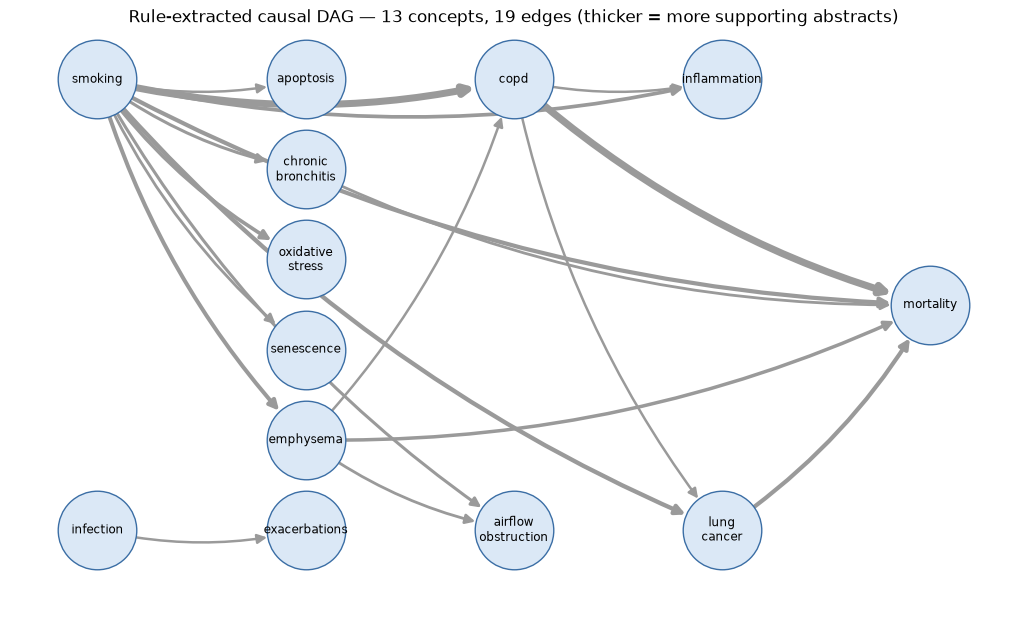

In [28]:
def layered_positions(G, sweeps=12):
    """Column = longest chain of causes before the node. Within a column, nodes are repeatedly re-sorted by the
    average height of their neighbours, which pulls connected nodes level with each other and reduces crossings."""
    layer = {}
    for n in nx.topological_sort(G):
        layer[n] = max((layer[p] + 1 for p in G.predecessors(n)), default=0)
    cols = {c: sorted(n for n in G if layer[n] == c) for c in set(layer.values())}
    rank = {n: i for nodes in cols.values() for i, n in enumerate(nodes)}
    height = lambda m: rank[m] / max(len(cols[layer[m]]) - 1, 1)
    for _ in range(sweeps):
        for nodes in cols.values():
            nodes.sort(key=lambda n: (np.mean([height(m) for m in nx.all_neighbors(G, n)]), n))
            rank.update({n: i for i, n in enumerate(nodes)})
    pos = {}
    for c, nodes in cols.items():
        ys = np.linspace(1, -1, len(nodes)) if len(nodes) > 1 else np.zeros(1)
        pos.update({n: (c * 2.2, y) for n, y in zip(nodes, ys)})
    return pos


def draw_dag(G, title, ax=None, path=None):
    pos = layered_positions(G)
    ax = ax or plt.subplots(figsize=(13, 7.5))[1]
    widths = [0.8 + 0.7 * d["n_docs"] ** 0.5 for _, _, d in G.edges(data=True)]
    nx.draw_networkx_edges(G, pos, ax=ax, width=widths, edge_color="#9a9a9a", arrowsize=14,
                           node_size=3200, connectionstyle="arc3,rad=0.12")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=3200, node_color="#dbe8f6", edgecolors="#3b6ea5")
    nx.draw_networkx_labels(G, pos, ax=ax, labels={n: n.replace("_", "\n") for n in G}, font_size=8.5)
    ax.set_title(title)
    ax.axis("off")
    if path:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(path, dpi=160, bbox_inches="tight")
    return ax


draw_dag(dag_rules, f"Rule-extracted causal DAG — {dag_rules.number_of_nodes()} concepts, "
                    f"{dag_rules.number_of_edges()} edges (thicker = more supporting abstracts)", path="figures/dag_rules.png")
plt.show()

In [29]:
edge_table(dag_rules)

,cause,effect,n_docs,n_sents,example
0,copd,mortality,38,39,COPD is an incurable disease and a leading cause of death worldwide.
1,smoking,copd,37,38,Pulmonologists have a vital role to play in advocating for the health of their patients and the wider population by ...
2,smoking,lung_cancer,11,11,"In the twenty- first century, there is widespread agreement that in addition to lung cancer, emphysema, and chronic ..."
3,lung_cancer,mortality,10,11,Lung cancer continues to be one of the most common causes of cancer death despite understanding the major cause of t...
4,smoking,mortality,10,10,Lung cancer continues to be one of the most common causes of cancer death despite understanding the major cause of t...
5,smoking,emphysema,9,10,"In the twenty- first century, there is widespread agreement that in addition to lung cancer, emphysema, and chronic ..."
6,smoking,inflammation,7,7,"CS triggers emphysematous changes accompanied by accumulated DNA damage, apoptosis of alveolar epithelia, and lung i..."
7,smoking,oxidative_stress,7,7,"Oxidative stress generated by tobacco smoking plays a role in reducing genomic integrity, promoting epithelial-mesen..."
8,emphysema,mortality,6,7,Chronic obstructive pulmonary disease (COPD) is one of the prevalent causes of worldwide mortality and encompasses t...
9,smoking,airflow_obstruction,4,4,"Inhalation of cigarette smoke causes inflammation of the airways, airway wall remodelling, mucus hypersecretion and ..."


### Step 3 summary
- **Entity schema:** 20 concepts with their aliases, plus an ignore list for false friends like "cell death".
- **Extraction:** the Step 2 rules, unchanged, run on every same-sentence concept pair.
- **Graph rules from the brief, all enforced in code:** aliases merged, self-loops impossible, evidence IDs on every edge,
  reviewed edges only, weak edges dropped, cycles broken by removing the weakest edge, final check `is_directed_acyclic_graph`.
- `pairs` (with `tagged` sentences) is saved in memory, so Step 5 can run DistilBERT on exactly the same candidates.

**Next (Step 4):** turn `dag_rules` into a Bayesian network with pgmpy and ask intervention questions.

---
<a id="step4"></a>

## Step 4 — Bayesian network on real survey data, and intervention queries

The DAG from Step 3 says **which** arrows exist. A Bayesian network also needs **how strong** each arrow is: a probability
table for every node given its causes (its *parents*), e.g. P(COPD | smoking, age). Text does not give us those numbers.
We learn them from **NHANES**, the US national health survey, which records smoking and lung diagnoses for real people.

Plan: download NHANES → code the variables → take the text DAG's arrows between measured concepts → add age as a confounder →
**test** the graph against the data → fit the probabilities → ask observational and `do(...)` questions.

### 4.1 Load NHANES 2013–2018
Three survey cycles are pooled for enough cases of rare diseases. Each cycle has three questionnaire files (demographics,
smoking, medical conditions), plus the official **linked mortality file**, which records who died by the end of 2019.
Files are cached in `data/nhanes/`.

In [30]:
from pgmpy.inference import CausalInference, VariableElimination
from pgmpy.metrics import ImpliedCIs, StructureScore
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

NHANES_DIR = Path("data/nhanes")
NHANES_CYCLES = {"H": 2013, "I": 2015, "J": 2017}    # cycle letter -> first survey year


def download_nhanes():
    NHANES_DIR.mkdir(parents=True, exist_ok=True)
    for letter, year in NHANES_CYCLES.items():
        for part in ("DEMO", "SMQ", "MCQ"):
            path = NHANES_DIR / f"{part}_{letter}.xpt"
            if not path.exists():
                urllib.request.urlretrieve(
                    f"https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{year}/DataFiles/{part}_{letter}.xpt", path)
        path = NHANES_DIR / f"MORT_{year}_{year + 1}.dat"
        if not path.exists():
            urllib.request.urlretrieve("https://ftp.cdc.gov/pub/Health_Statistics/NCHS/datalinkage/linked_mortality/"
                                       f"NHANES_{year}_{year + 1}_MORT_2019_PUBLIC.dat", path)


def load_cycle(letter, year):
    read = lambda part, cols: pd.read_sas(NHANES_DIR / f"{part}_{letter}.xpt", format="xport", encoding=None)[cols]
    # mortality file is fixed-width text; positions from the CDC's published layout
    mort = pd.read_fwf(NHANES_DIR / f"MORT_{year}_{year + 1}.dat", colspecs=[(0, 6), (14, 15), (15, 16)],
                       names=["SEQN", "ELIGSTAT", "MORTSTAT"], na_values=".")
    return (read("DEMO", ["SEQN", "RIDAGEYR"])
            .merge(read("SMQ", ["SEQN", "SMQ020", "SMQ040"]), on="SEQN")
            .merge(read("MCQ", ["SEQN", "MCQ160G", "MCQ160K", "MCQ160O", "MCQ230A", "MCQ230B", "MCQ230C", "MCQ230D"]),
                   on="SEQN")
            .merge(mort, on="SEQN", how="left"))


download_nhanes()
nhanes_raw = pd.concat([load_cycle(l, y) for l, y in NHANES_CYCLES.items()], ignore_index=True)
print(f"{len(nhanes_raw)} people answered the smoking and medical questionnaires")

/Users/divyanshrathore/Desktop/Coding/dl-ml-project/.venv/lib/python3.14/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


20893 people answered the smoking and medical questionnaires


### 4.2 Turn survey answers into network variables
| Node | NHANES question | States |
|---|---|---|
| `age` | age at interview (adults only) | 20-44, 45-64, 65+ |
| `smoking` | SMQ020 "smoked 100+ cigarettes in life?" + SMQ040 "smoke now?" | never, former, current |
| `copd` | MCQ160O "ever told you had COPD?" | yes, no |
| `emphysema` | MCQ160G "ever told you had emphysema?" | yes, no |
| `chronic_bronchitis` | MCQ160K "ever told you had chronic bronchitis?" | yes, no |
| `lung_cancer` | MCQ230A–D cancer type = 23 (lung) | yes, no |
| `mortality` | linked mortality file: died by 31 Dec 2019 | yes, no |

Answers "refused" / "don't know" (codes 7, 9) become missing, and those people are dropped.

In [31]:
adults = nhanes_raw[nhanes_raw.RIDAGEYR >= 20]
yes_no = lambda col: adults[col].map({1: "yes", 2: "no"})

nh = pd.DataFrame({
    "age": pd.cut(adults.RIDAGEYR, [19, 44, 64, 200], labels=["20-44", "45-64", "65+"]).astype(str),
    "smoking": pd.Series(np.select([adults.SMQ020 == 2, adults.SMQ040 == 3, adults.SMQ040.isin([1, 2])],
                                   ["never", "former", "current"], default=""), index=adults.index).replace("", None),
    "copd": yes_no("MCQ160O"),
    "emphysema": yes_no("MCQ160G"),
    "chronic_bronchitis": yes_no("MCQ160K"),
    "lung_cancer": np.where(adults[["MCQ230A", "MCQ230B", "MCQ230C", "MCQ230D"]].eq(23).any(axis=1), "yes", "no"),
    "mortality": adults.MORTSTAT.where(adults.ELIGSTAT == 1).map({1: "yes", 0: "no"}),
}).dropna().reset_index(drop=True)

print(f"{len(nh)} adults with complete answers")
pd.DataFrame({c: nh[c].value_counts() for c in nh.columns}).T.fillna(0).astype(int)

16904 adults with complete answers


,20-44,45-64,65+,current,former,never,no,yes
age,6971,5800,4133,0,0,0,0,0
smoking,0,0,0,3244,3946,9714,0,0
copd,0,0,0,0,0,0,16240,664
emphysema,0,0,0,0,0,0,16580,324
chronic_bronchitis,0,0,0,0,0,0,15901,1003
lung_cancer,0,0,0,0,0,0,16850,54
mortality,0,0,0,0,0,0,16032,872


### 4.3 Network structure = text DAG + age
We keep every arrow from Step 3's `dag_rules` whose **both ends are measured in NHANES**. Arrows touching unmeasured biology
(inflammation, oxidative stress, …) can't be fitted, so they stay in the text graph but drop out of the network.

We then add **age → every node**. None of our abstracts' extracted arrows mention age (it isn't in the entity schema), but age
is a textbook *confounder*. Older people have smoked longer and also get sick and die more, so ignoring age would mix up
"smokers get sick" with "older people get sick". This is the symbolic side doing its job: known domain knowledge is added on purpose
and documented, not guessed by a language model.

In [32]:
BN_NODES = ["smoking", "copd", "emphysema", "chronic_bronchitis", "lung_cancer", "mortality"]
text_edges = [(u, v) for u, v in dag_rules.edges if u in BN_NODES and v in BN_NODES]
unmeasured_edges = [(u, v) for u, v in dag_rules.edges if (u, v) not in text_edges]
age_edges = [("age", n) for n in BN_NODES]

print("arrows from the text DAG used in the network:")
for u, v in text_edges:
    print(f"   {u} -> {v}   ({dag_rules[u][v]['n_docs']} abstracts)")
print(f"\n{len(unmeasured_edges)} text arrows dropped because one end isn't measured in NHANES, e.g. {unmeasured_edges[:3]}")
print(f"{len(age_edges)} age arrows added from domain knowledge")

bn_edges = text_edges + age_edges
assert nx.is_directed_acyclic_graph(nx.DiGraph(bn_edges))

arrows from the text DAG used in the network:
   copd -> mortality   (38 abstracts)
   copd -> lung_cancer   (2 abstracts)
   smoking -> copd   (37 abstracts)
   smoking -> mortality   (10 abstracts)
   smoking -> lung_cancer   (11 abstracts)
   smoking -> emphysema   (9 abstracts)
   smoking -> chronic_bronchitis   (4 abstracts)
   lung_cancer -> mortality   (10 abstracts)
   chronic_bronchitis -> mortality   (3 abstracts)
   emphysema -> mortality   (6 abstracts)
   emphysema -> copd   (2 abstracts)

8 text arrows dropped because one end isn't measured in NHANES, e.g. [('infection', 'exacerbations'), ('copd', 'inflammation'), ('smoking', 'oxidative_stress')]
6 age arrows added from domain knowledge


### 4.4 Test the graph against the data (before trusting it)
Two checks, both standard ways to "test" a causal graph:

1. **Fit score (BIC).** How well each candidate graph explains the data, with a penalty for extra arrows. Higher is better.
   We compare: no arrows at all, age arrows only, text arrows only, and text + age.
2. **Implied independencies.** Every *missing* arrow is a claim. For example, if there is no arrow lung_cancer → emphysema,
   then once we know their shared causes, the two should be unrelated. A chi-square test checks each claim, and a small p-value means
   the data **disagrees**, so the text probably missed an arrow.

In [33]:
def as_bn(edges, nodes=("age", *BN_NODES)):
    model = DiscreteBayesianNetwork(edges)
    model.add_nodes_from(nodes)
    return model


bic = StructureScore(scoring_method="bic-d")
candidates = {"no arrows": [], "age arrows only": age_edges, "text arrows only": text_edges, "text + age (ours)": bn_edges}
pd.DataFrame({"BIC (higher = better)": {name: round(float(bic(X=nh, causal_graph=as_bn(e)))) for name, e in candidates.items()}})

,BIC (higher = better)
no arrows,-46728
age arrows only,-45276
text arrows only,-45740
text + age (ours),-45058


In [34]:
ci_results = (ImpliedCIs(ci_test="chi_square", show_progress=False).evaluate(X=nh, causal_graph=as_bn(bn_edges))
              .rename(columns={"p-value": "p_value"}))
ci_results["holds in data?"] = np.where(ci_results.p_value < 0.01, "NO", "yes")
print(f"{len(ci_results)} independence claims tested, {(ci_results.p_value < 0.01).sum()} rejected at p < 0.01")
ci_results.sort_values("p_value")

4 independence claims tested, 2 rejected at p < 0.01


,u,v,cond_vars,p_value,holds in data?
0,copd,chronic_bronchitis,"[age, smoking]",1.574915e-237,NO
3,emphysema,chronic_bronchitis,"[age, smoking]",1.910724e-98,NO
2,lung_cancer,chronic_bronchitis,"[smoking, age]",1.051481e-01,yes
1,lung_cancer,emphysema,"[smoking, age, copd]",9.818050e-01,yes


**How to read this:** a rejected claim (`NO`) points to a pair of nodes the data says are connected but our graph treats as
unrelated.

- **BIC:** the text arrows *do* add information. "text + age" scores best, ahead of "age only". So the extracted graph is useful, not just decoration.
- **Rejected claims:** *chronic bronchitis* is strongly linked to *COPD* and *emphysema*, even among people of the same age and smoking status.
  That makes sense medically: chronic bronchitis and emphysema are the two main forms of COPD, so the three diagnoses overlap. The text
  graph has emphysema → COPD but no arrow involving chronic bronchitis. The extractor missed it, because papers describe it as
  "COPD *includes* chronic bronchitis", which is not cause-and-effect wording.

We report these honestly and do **not** quietly add arrows the text never proposed. The queries below focus on smoking's effects,
which come from the best-supported part of the graph.

### 4.5 Fit the probability tables
`DiscreteBayesianEstimator` counts how often each outcome occurs for every combination of parents, with a small **BDeu prior**: a few
"imaginary" observations spread evenly. This prevents 0% or 100% estimates when a combination is rare (only ~50 people have lung cancer).

In [35]:
bn = as_bn(bn_edges).fit(nh, estimator=DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=10))
assert bn.check_model()
print("Each node now has a probability table for every combination of its parents:")
print({n: list(bn.get_parents(n)) for n in bn.nodes})

# one slice of the COPD table, readable: P(copd = yes | smoking, age), for people without emphysema
copd_cpd = bn.get_cpds("copd")
slice_ = {(s, a): float(copd_cpd.get_value(copd="yes", smoking=s, age=a, emphysema="no"))
          for s in ["never", "former", "current"] for a in ["20-44", "45-64", "65+"]}
(pd.Series(slice_).unstack() * 100).round(2).rename_axis(index="smoking", columns="age  ->  P(COPD) in %")

Each node now has a probability table for every combination of its parents:
{'copd': ['smoking', 'emphysema', 'age'], 'mortality': ['copd', 'smoking', 'lung_cancer', 'chronic_bronchitis', 'emphysema', 'age'], 'lung_cancer': ['copd', 'smoking', 'age'], 'smoking': ['age'], 'emphysema': ['smoking', 'age'], 'chronic_bronchitis': ['smoking', 'age'], 'age': []}


age -> P(COPD) in %,20-44,45-64,65+
smoking,,,
current,1.00,9.43,11.65
former,0.56,4.01,8.13
never,0.12,0.80,2.67


### 4.6 Seeing vs doing: observational and interventional queries
- **Seeing**, P(COPD | smoking = current): "among people who *happen* to smoke, how many have COPD?" This mixes in age:
  current smokers in the survey are younger than former smokers.
- **Doing**, P(COPD | **do**(smoking = current)): "if we *made* everyone smoke, how many would have COPD?" pgmpy cuts the
  arrow age → smoking and averages over the whole population's ages (the *back-door adjustment*). Only the causal path remains.

Sanity check first: the network's "seeing" answers should match the raw survey percentages.

In [36]:
seeing_engine = VariableElimination(bn)
doing_engine = CausalInference(bn)
p_yes = lambda factor, var: float(factor.get_value(**{var: "yes"}))


def seeing(var, evidence=None):
    return p_yes(seeing_engine.query([var], evidence=evidence or {}, show_progress=False), var)


def doing(var, do):
    return p_yes(doing_engine.query([var], do=do, show_progress=False), var)


check = pd.DataFrame([dict(outcome=o, smoking=s, survey=(nh[nh.smoking == s][o] == "yes").mean(),
                           network=seeing(o, {"smoking": s}))
                      for o in ["copd", "mortality"] for s in ["never", "former", "current"]])
check.round(4)

,outcome,smoking,survey,network
0,copd,never,0.0100,0.0102
1,copd,former,0.0712,0.0716
2,copd,current,0.0882,0.0886
3,mortality,never,0.0344,0.0348
4,mortality,former,0.0917,0.0933
5,mortality,current,0.0543,0.0554


In [37]:
rows = []
for outcome in ["copd", "emphysema", "chronic_bronchitis", "lung_cancer", "mortality"]:
    row = {"outcome": outcome}
    for s in ["never", "former", "current"]:
        row[f"seeing: {s}"] = seeing(outcome, {"smoking": s})
        row[f"doing: do({s})"] = doing(outcome, {"smoking": s})
    row["causal risk ratio current/never"] = row["doing: do(current)"] / row["doing: do(never)"]
    rows.append(row)
seeing_vs_doing = pd.DataFrame(rows).set_index("outcome")
(seeing_vs_doing.iloc[:, :-1] * 100).round(2).join(seeing_vs_doing.iloc[:, -1:].round(2))

,seeing: never,doing: do(never),seeing: former,doing: do(former),seeing: current,doing: do(current),causal risk ratio current/never
outcome,,,,,,,
copd,1.02,1.12,7.16,5.24,8.86,10.42,9.32
emphysema,0.35,0.37,3.89,2.82,4.36,5.35,14.30
chronic_bronchitis,3.57,3.73,8.02,7.25,10.61,10.87,2.91
lung_cancer,0.08,0.09,0.93,0.62,0.45,0.57,6.57
mortality,3.48,3.85,9.33,6.40,5.54,6.93,1.80


All values are percentages, except the last column. Look at **mortality**. In the raw survey (*seeing*), former smokers die
**more** often than current smokers (9.3% vs 5.5%), which would wrongly suggest that quitting is dangerous. The reason is age:
former smokers are on average much older. With *doing*, every group gets the same age mix, and the order flips
(6.4% vs 6.9%). Reading percentages straight off the data, or straight out of text, gives the wrong conclusion. The causal
query gives the right one.

### 4.7 The documented causal queries
These are the questions the deliverable promises to answer. Each one is a formal `do(...)` query on the fitted network.

In [38]:
p_copd_now = seeing("copd")
p_copd_nobody_smokes = doing("copd", {"smoking": "never"})
p_death_copd = doing("mortality", {"copd": "yes"})
p_death_no_copd = doing("mortality", {"copd": "no"})
lc = seeing_vs_doing.loc["lung_cancer"]
mort = seeing_vs_doing.loc["mortality"]

causal_queries = pd.DataFrame([
    ("Q1", "If everyone smoked vs nobody smoked, how much more COPD?",
     "P(copd | do(smoking=current)) / P(copd | do(smoking=never))",
     f"{seeing_vs_doing.loc['copd', 'causal risk ratio current/never']:.1f}x"),
    ("Q2", "What share of today's COPD would disappear if nobody had ever smoked?",
     "[P(copd) - P(copd | do(smoking=never))] / P(copd)",
     f"{(p_copd_now - p_copd_nobody_smokes) / p_copd_now:.0%}  ({p_copd_now:.2%} -> {p_copd_nobody_smokes:.2%})"),
    ("Q3", "Does quitting help? COPD risk for former vs current smokers, same age mix",
     "P(copd | do(former)) vs P(copd | do(current))",
     f"{seeing_vs_doing.loc['copd', 'doing: do(former)']:.2%} vs {seeing_vs_doing.loc['copd', 'doing: do(current)']:.2%}"),
    ("Q4", "How much does smoking raise lung cancer risk?",
     "P(lung_cancer | do(current)) / P(lung_cancer | do(never))",
     f"{lc['causal risk ratio current/never']:.1f}x  ({lc['doing: do(never)']:.2%} -> {lc['doing: do(current)']:.2%})"),
    ("Q5", "How much does smoking raise the chance of dying during follow-up?",
     "P(mortality | do(current)) / P(mortality | do(never))",
     f"{mort['causal risk ratio current/never']:.1f}x  ({mort['doing: do(never)']:.2%} -> {mort['doing: do(current)']:.2%})"),
    ("Q6", "If we could give someone COPD (or prevent it), how does their risk of dying change?",
     "P(mortality | do(copd=yes)) vs P(mortality | do(copd=no))",
     f"{p_death_copd:.2%} vs {p_death_no_copd:.2%}  ({p_death_copd / p_death_no_copd:.1f}x)"),
], columns=["id", "question", "formal query", "answer"])
causal_queries

,id,question,formal query,answer
0,Q1,"If everyone smoked vs nobody smoked, how much more COPD?",P(copd | do(smoking=current)) / P(copd | do(smoking=never)),9.3x
1,Q2,What share of today's COPD would disappear if nobody had ever smoked?,[P(copd) - P(copd | do(smoking=never))] / P(copd),72% (3.96% -> 1.12%)
2,Q3,"Does quitting help? COPD risk for former vs current smokers, same age mix",P(copd | do(former)) vs P(copd | do(current)),5.24% vs 10.42%
3,Q4,How much does smoking raise lung cancer risk?,P(lung_cancer | do(current)) / P(lung_cancer | do(never)),6.6x (0.09% -> 0.57%)
4,Q5,How much does smoking raise the chance of dying during follow-up?,P(mortality | do(current)) / P(mortality | do(never)),1.8x (3.85% -> 6.93%)
5,Q6,"If we could give someone COPD (or prevent it), how does their risk of dying change?",P(mortality | do(copd=yes)) vs P(mortality | do(copd=no)),8.19% vs 4.82% (1.7x)


### Step 4 summary
- **Data:** NHANES 2013–2018, adults with complete answers, linked to deaths through 2019.
- **Structure:** text arrows between measured concepts plus age as a documented confounder. It was tested with BIC and with independence
  tests before being trusted.
- **Queries:** six formal `do(...)` questions answered. Comparing "seeing" with "doing" shows why a causal model is needed:
  raw percentages mix the effect of smoking with the effect of age.
- **Limitations (stated honestly):** diagnoses are self-reported; follow-up for deaths is short (1–7 years, depending on cycle);
  lung cancer is rare in the survey, so its numbers are uncertain; and income, occupation and pollution are not in the network,
  so the results assume no hidden confounders beyond age.

**Next (Step 5):** fine-tune DistilBERT on SemEval and run it on the same PubMed candidate pairs.

---
<a id="step5"></a>

## Step 5 — DL model: fine-tuning DistilBERT for causal relation extraction

**DistilBERT** is a smaller, faster version of BERT (Devlin et al., 2019). It keeps about 97% of BERT's language understanding
with 40% fewer parameters. It has already learned general English from a huge amount of text. **Fine-tuning** means training it a
little more on our labelled SemEval sentences so it learns one specific job.

**Same task as the rules:** read a sentence with `<e1>…</e1>` and `<e2>…</e2>` markers and answer `e1->e2`, `e2->e1` or `none`.

### 5.1 Tokenizer with entity markers
A transformer reads *tokens* (word pieces). We add our four markers as **special tokens**, so the model sees each one as a
single new symbol and doesn't split it into `<`, `e`, `1`, `>`.

In [39]:
import torch
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
torch.manual_seed(SEED)

MODEL_NAME = "distilbert-base-uncased"
MODEL_DIR = Path("models/distilbert-causal")
RETRAIN = False                      # True = train again even if a saved model exists
LABELS = ["none", "e1->e2", "e2->e1"]
LABEL_ID = {label: i for i, label in enumerate(LABELS)}
MARKERS = ["<e1>", "</e1>", "<e2>", "</e2>"]
MAX_LEN = 256
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("training device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.add_special_tokens({"additional_special_tokens": MARKERS})
print(tokenizer.tokenize("The <e1>burst</e1> has been caused by water hammer <e2>pressure</e2>."))

training device: mps


['the', '<e1>', 'burst', '</e1>', 'has', 'been', 'caused', 'by', 'water', 'hammer', '<e2>', 'pressure', '</e2>', '.']


### 5.2 Batching, prediction and training helpers
- Sentences in a batch are padded to the longest one in that batch (*dynamic padding*), which keeps training fast.
- `predict` returns the most likely label **and** its probability. The probability becomes the triple's `confidence`.
- Training uses AdamW with a learning rate that warms up and then decays linearly, the standard recipe for fine-tuning BERT models.
  After every epoch (one full pass over the training data), we score on **validation** and keep the best version.

In [40]:
def make_loader(texts, labels=None, batch_size=32, shuffle=False):
    enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN)
    items = [{"input_ids": ids, "attention_mask": mask} for ids, mask in zip(enc["input_ids"], enc["attention_mask"])]
    if labels is not None:
        for item, y in zip(items, labels):
            item["labels"] = y
    return DataLoader(items, batch_size=batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED),
                      collate_fn=lambda batch: tokenizer.pad(batch, return_tensors="pt"))


@torch.no_grad()
def predict(model, texts, batch_size=64):
    """Returns (labels, confidences); label 'none' is returned as None, matching the rules' output."""
    model.eval()
    probs = []
    for batch in make_loader(texts, batch_size=batch_size):
        logits = model(**{k: v.to(device) for k, v in batch.items()}).logits
        probs.append(torch.softmax(logits, dim=-1).cpu())
    probs = torch.cat(probs)
    conf, idx = probs.max(dim=-1)
    labels = [None if LABELS[i] == "none" else LABELS[i] for i in idx.tolist()]
    return labels, conf.numpy()


def train_distilbert(train_df, val_df, epochs=4, lr=5e-5, batch_size=32):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=LABEL_ID)
    model.resize_token_embeddings(len(tokenizer))      # make room for the 4 new marker tokens
    model.to(device)

    y_train = train_df.gold_dir.fillna("none").map(LABEL_ID).tolist()
    loader = make_loader(train_df.tagged, y_train, batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = epochs * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

    history, best_f1 = [], -1.0
    for epoch in range(1, epochs + 1):
        model.train()
        start, losses = time.time(), []
        for batch in loader:
            out = model(**{k: v.to(device) for k, v in batch.items()})
            out.loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            losses.append(out.loss.item())
        val_pred, _ = predict(model, val_df.tagged)
        s = score(val_df.gold_dir, val_pred)
        history.append(dict(epoch=epoch, train_loss=round(float(np.mean(losses)), 4), minutes=round((time.time() - start) / 60, 1),
                            val_precision=s["precision"], val_recall=s["recall"], val_f1=s["f1"]))
        print(history[-1])
        if s["f1"] > best_f1:
            best_f1 = s["f1"]
            model.save_pretrained(MODEL_DIR)
            tokenizer.save_pretrained(MODEL_DIR)
    (MODEL_DIR / "history.json").write_text(json.dumps(history, indent=1))
    return history

### 5.3 Train (or load the saved model)
Training takes several minutes on a laptop GPU (Apple M-series `mps`). The best epoch is saved to `models/distilbert-causal/`,
so re-running the notebook loads it instead of retraining. Set `RETRAIN = True` to train from scratch.

In [41]:
if RETRAIN or not (MODEL_DIR / "history.json").exists():
    train_distilbert(df[df.split == "train"], df[df.split == "val"])
training_history = pd.DataFrame(json.loads((MODEL_DIR / "history.json").read_text()))
bert = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(device)
training_history

W1025 13:03:40.536000 12574 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,epoch,train_loss,minutes,val_precision,val_recall,val_f1
0,1,0.3198,2.1,0.838,0.827,0.832
1,2,0.0789,6.5,0.912,0.833,0.871
2,3,0.0463,6.2,0.875,0.887,0.881
3,4,0.0153,4.8,0.875,0.887,0.881


### 5.4 DistilBERT vs rules on validation
Same sentences, same `score()` function as in Step 2. The **test** set is still untouched (Step 6).

In [42]:
df["bert_pred"], df["bert_conf"] = predict(bert, df.tagged)

val = df[df.split == "val"]
pd.DataFrame({"rules (Step 2)": score(val.gold_dir, val.rules_pred),
              "DistilBERT": score(val.gold_dir, val.bert_pred)}).T

,correct,predicted_causal,truly_causal,precision,recall,f1
rules (Step 2),74.0,79.0,150.0,0.937,0.493,0.646
DistilBERT,133.0,152.0,150.0,0.875,0.887,0.881


In [43]:
causal_val = val[val.gold_dir.notna()]
outcome = lambda pred: np.select([pred == causal_val.gold_dir, pred.notna()], ["right arrow", "wrong arrow"], "missed")
pd.crosstab(pd.Series(outcome(causal_val.rules_pred), name="rules"), pd.Series(outcome(causal_val.bert_pred), name="DistilBERT"))

DistilBERT,missed,right arrow
rules,,
missed,17,59
right arrow,0,74


In [44]:
print("Causal sentences DistilBERT gets right but the rules missed:\n")
for t in causal_val[(causal_val.bert_pred == causal_val.gold_dir) & causal_val.rules_pred.isna()].tagged.head(8):
    print(" -", t)
print("\nDistilBERT false alarms (not causal, but it said causal):\n")
for r in val[val.gold_dir.isna() & val.bert_pred.notna()].head(6).itertuples():
    print(f" - [{r.relation}] {r.tagged}")

Causal sentences DistilBERT gets right but the rules missed:

 - He had chest pains and <e1>headaches</e1> from <e2>mold</e2> in the bedrooms.
 - The continuing Nigerian <e1>outbreak</e1> is the biggest ever caused by the <e2>vaccine</e2>.
 - The metal <e1>ball</e1> makes a ding ding ding <e2>noise</e2> when it swings back and hits the metal body of the lamp.
 - Tension Release by Mega Food contains Sensoril, a clinically studied extract of a Ashwagandha that helps to inhibit fatigue and physical <e1>tension</e1> from everyday <e2>stress</e2>.
 - The <e1>law</e1> established a major <e2>redistribution</e2> of territorial sovereignty within the Empire.
 - This article discusses the ethics of the Soldier of Fortune's guns-for-hire <e1>advertisements</e1> that resulted in several <e2>murders</e2> across the United States.
 - For decades, most of the nation's renewable <e1>power</e1> has come from <e2>dams</e2>, which supplied cheap electricity without requiring fossil fuels.
 - There were

### 5.5 Run DistilBERT on the PubMed candidate pairs and build its graph
Exactly the same 6,051 pairs from Step 3, and exactly the same graph cleaning: review file → at least 2 abstracts → break cycles.
Only the extractor changes, so any difference between the two graphs comes from the extractor.

In [45]:
pairs["bert_pred"], pairs["bert_conf"] = predict(bert, pairs.tagged)
print(f"DistilBERT calls {pairs.bert_pred.notna().sum()} of {len(pairs)} PubMed pairs causal "
      f"(rules: {pairs.rules_pred.notna().sum()})")
pd.crosstab(pairs.rules_pred.fillna("none"), pairs.bert_pred.fillna("none"),
            rownames=["rules"], colnames=["DistilBERT"])

DistilBERT calls 1396 of 6051 PubMed pairs causal (rules: 283)


DistilBERT,e1->e2,e2->e1,none
rules,,,
e1->e2,204,4,17
e2->e1,23,32,3
none,623,510,4635


In [46]:
def pubmed_dag(pred_col, conf_col, source, review_file):
    """The full Step 3 graph pipeline for one extractor. Returns (raw graph, final DAG, cycle log)."""
    triples = []
    for row in pairs[pairs[pred_col].notna()].itertuples():
        cause, effect = (row.e1, row.e2) if getattr(row, pred_col) == "e1->e2" else (row.e2, row.e1)
        conf = float(getattr(row, conf_col)) if conf_col else 1.0
        triples.append(CausalTriple(cause, effect, row.doc_id, row.sent_id, source, conf))
    G = build_graph(list(dict.fromkeys(triples)), sentence_of)
    G_kept = apply_review(G, review_file)
    G_kept.remove_edges_from([(u, v) for u, v, d in G_kept.edges(data=True) if d["n_docs"] < MIN_DOCS])
    G_kept.remove_nodes_from([n for n in list(G_kept) if G_kept.degree(n) == 0])
    dag, log = break_cycles(G_kept)
    assert nx.is_directed_acyclic_graph(dag)
    return G, dag, log


G_bert_raw, dag_bert, cycle_log_bert = pubmed_dag("bert_pred", "bert_conf", "distilbert", Path("data/review/edges_distilbert.csv"))
print(f"DistilBERT graph: {G_bert_raw.number_of_edges()} raw edges -> final DAG with {dag_bert.number_of_nodes()} concepts, "
      f"{dag_bert.number_of_edges()} edges ({len(cycle_log_bert)} removed to break cycles)")
cycle_log_bert

review: 0 of 178 edges reviewed, 0 rejected
DistilBERT graph: 178 raw edges -> final DAG with 18 concepts, 59 edges (59 removed to break cycles)


,cause,effect,n_docs,cycle
0,mortality,smoking,12,copd -> mortality -> smoking -> copd
1,mortality,chronic_bronchitis,2,copd -> mortality -> chronic_bronchitis -> copd
2,airflow_obstruction,mortality,5,mortality -> emphysema -> airflow_obstruction -> mortality
3,mortality,emphysema,8,copd -> mortality -> emphysema -> airflow_obstruction -> copd
4,lung_cancer,oxidative_stress,2,copd -> mortality -> lung_cancer -> oxidative_stress -> smoking -> copd
5,lung_cancer,airflow_obstruction,2,copd -> mortality -> lung_cancer -> airflow_obstruction -> copd
6,mortality,lung_cancer,4,mortality -> lung_cancer -> mortality
7,mortality,copd,10,copd -> mortality -> copd
8,exacerbations,airflow_obstruction,2,copd -> mortality -> exacerbations -> airflow_obstruction -> copd
9,mortality,exacerbations,3,mortality -> exacerbations -> mortality


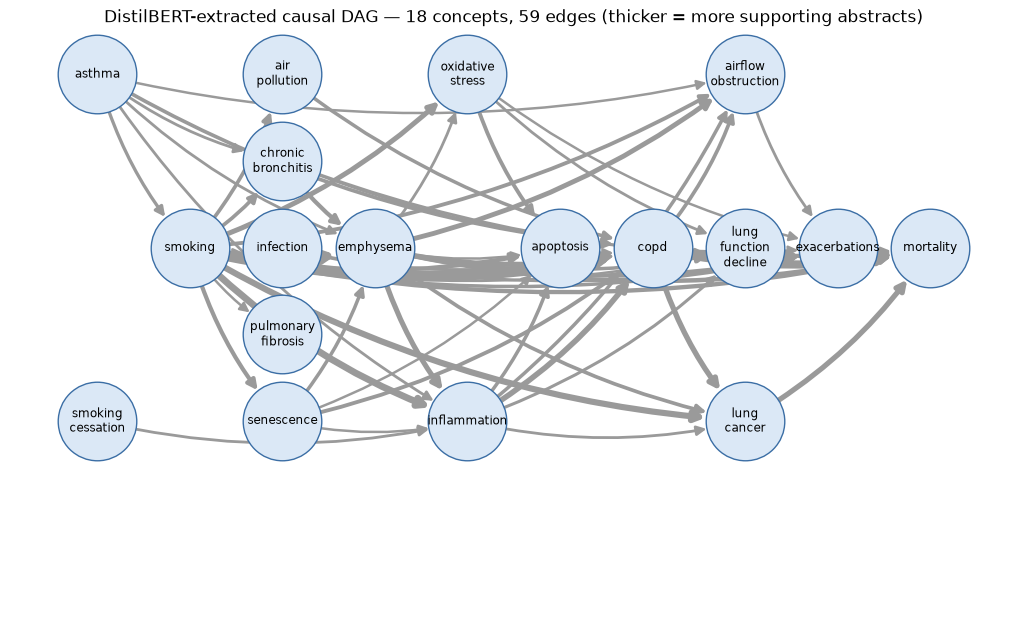

In [47]:
draw_dag(dag_bert, f"DistilBERT-extracted causal DAG — {dag_bert.number_of_nodes()} concepts, "
                   f"{dag_bert.number_of_edges()} edges (thicker = more supporting abstracts)", path="figures/dag_distilbert.png")
plt.show()

In [48]:
rules_edges, bert_edges = set(dag_rules.edges), set(dag_bert.edges)
edge_compare = pd.DataFrame(
    [dict(cause=u, effect=v,
          found_by="both" if (u, v) in rules_edges and (u, v) in bert_edges else "rules only" if (u, v) in rules_edges else "DistilBERT only",
          docs_rules=dag_rules.edges[u, v]["n_docs"] if (u, v) in rules_edges else 0,
          docs_bert=dag_bert.edges[u, v]["n_docs"] if (u, v) in bert_edges else 0)
     for u, v in sorted(rules_edges | bert_edges)])
print(edge_compare.found_by.value_counts().to_string())
edge_compare.sort_values(["found_by", "docs_bert"], ascending=[True, False], ignore_index=True)

found_by
DistilBERT only    41
both               18
rules only          1


,cause,effect,found_by,docs_rules,docs_bert
0,inflammation,copd,DistilBERT only,0,21
1,emphysema,inflammation,DistilBERT only,0,17
2,copd,exacerbations,DistilBERT only,0,15
3,emphysema,exacerbations,DistilBERT only,0,11
4,chronic_bronchitis,emphysema,DistilBERT only,0,10
5,oxidative_stress,apoptosis,DistilBERT only,0,8
6,senescence,copd,DistilBERT only,0,8
7,asthma,copd,DistilBERT only,0,7
8,copd,airflow_obstruction,DistilBERT only,0,7
9,emphysema,lung_cancer,DistilBERT only,0,7


### 5.6 Why does DistilBERT over-generate on PubMed? (domain shift)
DistilBERT scores 0.88 F1 on SemEval, but its PubMed graph needed **59 edges** removed to break cycles, including "COPD → smoking"
and "mortality → smoking". Three diagnostics:

In [49]:
conf_compare = pd.DataFrame({
    "SemEval validation": val[val.bert_pred.notna()].bert_conf.describe(percentiles=[.1, .25, .5]),
    "PubMed pairs": pairs[pairs.bert_pred.notna()].bert_conf.describe(percentiles=[.1, .25, .5]),
}).loc[["count", "10%", "25%", "50%"]].round(3)
print("1) Confidence of DistilBERT's causal calls:")
conf_compare

1) Confidence of DistilBERT's causal calls:


,SemEval validation,PubMed pairs
count,152.000,1396.000
10%,0.961,0.570
25%,0.984,0.797
50%,0.989,0.958


In [50]:
by_sentence = pairs.groupby("sent_id").agg(n_pairs=("e1", "size"),
                                           bert=("bert_pred", lambda s: s.notna().sum()),
                                           rules=("rules_pred", lambda s: s.notna().sum()))
by_sentence["pairs in sentence"] = pd.cut(by_sentence.n_pairs, [0, 1, 3, 6, 100], labels=["1", "2-3", "4-6", "7+"])
rate = by_sentence.groupby("pairs in sentence", observed=True)[["n_pairs", "bert", "rules"]].sum()
print("2) Share of candidate pairs called causal, by how many pairs the sentence has:")
pd.DataFrame({"pairs": rate.n_pairs, "DistilBERT": (rate.bert / rate.n_pairs).round(3), "rules": (rate.rules / rate.n_pairs).round(3)})

2) Share of candidate pairs called causal, by how many pairs the sentence has:


,pairs,DistilBERT,rules
pairs in sentence,,,
1,930,0.161,0.031
2-3,1700,0.244,0.062
4-6,1542,0.244,0.049
7+,1879,0.242,0.038


In [51]:
calls = pairs[pairs.bert_pred.notna()].copy()
calls["cause"] = np.where(calls.bert_pred == "e1->e2", calls.e1, calls.e2)
calls["effect"] = np.where(calls.bert_pred == "e1->e2", calls.e2, calls.e1)
print("3) Backwards calls, with DistilBERT's confidence:\n")
for cause, effect in [("copd", "smoking"), ("mortality", "smoking")]:
    for r in calls[(calls.cause == cause) & (calls.effect == effect)].sort_values("bert_conf", ascending=False).head(3).itertuples():
        print(f"  {cause} -> {effect}  [{r.bert_conf:.2f}]  {r.tagged[:200]}")

3) Backwards calls, with DistilBERT's confidence:

  copd -> smoking  [0.99]  Tobacco smoke remains the main cause of <e1>COPD</e1>, though <e2>smoking</e2>-related limitation of the flow is rather subjective.
  copd -> smoking  [0.99]  Lung cancer and <e1>chronic obstructive pulmonary disease</e1> are leading causes of morbidity and mortality worldwide, and <e2>cigarette smoking</e2> is a main risk factor for both.
  copd -> smoking  [0.99]  Most-reported main causes of <e1>COPD</e1> were: <e2>smoking</e2> (57.5%), illnesses/conditions (53.8%) and pollutants (44.3%).
  mortality -> smoking  [0.99]  COPD is a leading cause of <e1>mortality</e1> worldwide, and <e2>cigarette smoke</e2> is a pivotal risk factor.
  mortality -> smoking  [0.99]  Lung cancer and chronic obstructive pulmonary disease are leading causes of morbidity and <e1>mortality</e1> worldwide, and <e2>cigarette smoking</e2> is a main risk factor for both.
  mortality -> smoking  [0.99]  COPD and lung cancer are leading c

**What this shows:**
1. **Confidence doesn't separate right from wrong.** The backwards calls above have ~0.99 confidence. On PubMed the model is less sure on average
   (lower 10%/25% quantiles than on SemEval), but a confidence cut-off would remove good and bad calls alike.
2. **The model says "causal" far more often on PubMed:** about 24% of pairs, against 3–6% for the rules, and it stays near 24%
   even in sentences crowded with concepts. SemEval always marks **one** pair per sentence, so the model never learned to ask
   "is *this particular* pair the cause and effect, or just two words in a causal sentence?"
3. **Direction mistakes on new phrasing.** "The most common cause of **COPD** is chronic **tobacco** inhalation" came out backwards with 0.99 confidence.

This is the gap the project brief describes. The language model reads fluently, but on its own it produces contradictions
(arrows in both directions) and has no calibrated sense of uncertainty. The symbolic stage catches the contradictions (cycle breaking),
but it can't tell which direction is *true* when both are well supported. That needs labelled PubMed examples, which is Step 6's job.

### Step 5 summary
- DistilBERT was fine-tuned on the same SemEval training sentences, with the best epoch picked on validation.
- On validation it is compared with the rules using the same scoring function. The **test** comparison comes in Step 6.
- On PubMed it labels the same candidate pairs, and its graph went through the same review, support and cycle rules.
  It finds far more edges than the rules, but it also over-generates: pair confusion, direction errors, and confidence that is
  high even when it is wrong. Domain shift from short general sentences to scientific abstracts.

**Next (Step 6):** the fair comparison. Precision/recall/F1 on the held-out **test** set, edge precision of both graphs against
a reference list of known causal facts, and a check of the causal queries.

---
<a id="step6"></a>

## Step 6 — The fair comparison

Three separate evaluations, as the brief asks: **relation extraction** is scored separately from **the final graph**.

1. **SemEval test set:** held out since Step 1. Rules vs DistilBERT on sentences neither has ever seen.
2. **PubMed sample:** the same scores on 300 PubMed pairs. These pairs have no human labels, so they were labelled by an
   **instruction model (Claude)**, and that labeller was itself evaluated first against SemEval's human gold labels.
3. **The graphs:** edge precision of both DAGs against a cited reference list, plus a check of Step 4's causal answers against published figures.

### 6.1 Building the label samples (blind and stratified)
**Labelling guideline (fixed before labelling):** a pair is causal (`e1->e2` or `e2->e1`) when the sentence itself *claims* that one
concept causes, leads to, induces, worsens, contributes to, increases the risk of, or is a cause / risk factor of the other. Hedged
claims ("may contribute to") count. Mere association ("associated with", "correlated with", "higher in"), co-listing, negated
claims, and claims about *other* concepts in the sentence are `none`.

**Blind:** the labeller only sees `item` and the marked sentence, never the extractors' predictions.

**Stratified:** a random sample would be mostly "none". We sample from four groups (both extractors say causal / rules only /
DistilBERT only / neither) and give each labelled pair a **weight** = (pairs in its group) ÷ (pairs sampled from its group), so the
estimates still describe all 6,051 pairs.

In [52]:
LABEL_DIR = Path("data/labels")
LABEL_DIR.mkdir(parents=True, exist_ok=True)

pairs["stratum"] = np.select(
    [pairs.rules_pred.notna() & pairs.bert_pred.notna(), pairs.rules_pred.notna(), pairs.bert_pred.notna()],
    ["both", "rules only", "DistilBERT only"], "neither")
SAMPLE_SIZES = {"both": 60, "rules only": 20, "DistilBERT only": 110, "neither": 110}
pm_sample = pd.concat([pairs[pairs.stratum == s].sample(min(n, (pairs.stratum == s).sum()), random_state=SEED)
                       for s, n in SAMPLE_SIZES.items()])
pm_sample["weight"] = pm_sample.stratum.map(pairs.stratum.value_counts()) / pm_sample.stratum.map(pm_sample.stratum.value_counts())
pm_sample = pm_sample.sample(frac=1, random_state=SEED)          # shuffle so groups are mixed
pm_sample["item"] = [f"P{i:03d}" for i in range(1, len(pm_sample) + 1)]

# SemEval check set for the labeller: 75 causal + 75 non-causal test sentences, gold labels hidden from the labeller
test = df[df.split == "test"]
se_sample = pd.concat([test[test.gold_dir.notna()].sample(75, random_state=SEED),
                       test[test.gold_dir.isna()].sample(75, random_state=SEED)]).sample(frac=1, random_state=SEED)
se_sample["item"] = [f"S{i:03d}" for i in range(1, len(se_sample) + 1)]

# The label files belong to ONE exact sample. Write the blind files once; on every later run, check the sample is identical,
# so labels can never silently attach to the wrong sentences (e.g. if PubMed abstracts were re-downloaded).
for sample, name in [(pm_sample, "pubmed_blind.csv"), (se_sample, "semeval_blind.csv")]:
    path = LABEL_DIR / name
    if not path.exists():
        sample[["item", "tagged"]].to_csv(path, index=False)
    stored = pd.read_csv(path)
    assert stored.item.tolist() == sample.item.tolist() and stored.tagged.tolist() == sample.tagged.tolist(), (
        f"{name} no longer matches the drawn sample: the labels in data/labels/ would be misaligned. "
        "Restore the original data/pubmed/abstracts.jsonl cache.")
pd.DataFrame({"pairs": pairs.stratum.value_counts(), "sampled": pm_sample.stratum.value_counts(),
              "weight": pm_sample.groupby("stratum").weight.first().round(2)})

,pairs,sampled,weight
stratum,,,
DistilBERT only,1133,110,10.30
both,263,60,4.38
neither,4635,110,42.14
rules only,20,20,1.00


### 6.2 SemEval test set: rules vs DistilBERT
Both extractors were fixed before this point: rules tuned on train, DistilBERT's epoch picked on validation. This is the first and only
time they see the test set. The 95% intervals come from a **bootstrap**: we re-draw the test set with replacement 1,000 times and
look at how much the score moves. The interval shows how much of the difference could be luck.

In [53]:
def weighted_score(gold, pred, weight=None):
    """Directional precision / recall / F1 on the causal class, with optional per-row weights."""
    gold, pred = pd.Series(gold).reset_index(drop=True), pd.Series(pred).reset_index(drop=True)
    w = np.ones(len(gold)) if weight is None else np.asarray(weight, dtype=float)
    tp = (w * (pred.notna() & (pred == gold))).sum()
    n_pred, n_gold = (w * pred.notna()).sum(), (w * gold.notna()).sum()
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_gold if n_gold else 0.0
    return {"precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0.0}


def bootstrap_f1(gold, pred, weight=None, strata=None, n=1000):
    """95% interval of F1; resampling happens within each stratum when strata are given."""
    rng = np.random.default_rng(SEED)
    gold, pred = pd.Series(gold).reset_index(drop=True), pd.Series(pred).reset_index(drop=True)
    w = np.ones(len(gold)) if weight is None else np.asarray(weight, dtype=float)
    groups = [np.arange(len(gold))] if strata is None else [np.flatnonzero(np.asarray(strata) == s) for s in np.unique(strata)]
    f1s = []
    for _ in range(n):
        idx = np.concatenate([rng.choice(g, len(g)) for g in groups])
        f1s.append(weighted_score(gold.iloc[idx], pred.iloc[idx], w[idx])["f1"])
    return np.percentile(f1s, [2.5, 97.5])


def score_table(gold, preds, weight=None, strata=None):
    rows = {}
    for name, pred in preds.items():
        s = weighted_score(gold, pred, weight)
        lo, hi = bootstrap_f1(gold, pred, weight, strata)
        rows[name] = {"precision": s["precision"], "recall": s["recall"], "f1": s["f1"], "f1 95% interval": f"{lo:.2f} - {hi:.2f}"}
    return pd.DataFrame(rows).T.round(3)


test = df[df.split == "test"]
semeval_test_scores = score_table(test.gold_dir, {"rules": test.rules_pred, "DistilBERT": test.bert_pred})
semeval_test_scores

,precision,recall,f1,f1 95% interval
rules,0.943396,0.609756,0.740741,0.69 - 0.78
DistilBERT,0.900901,0.914634,0.907716,0.88 - 0.93


### 6.3 How good is the labeller? (Claude vs SemEval's human labels)
Before trusting Claude's PubMed labels, we test Claude on 150 SemEval **test** sentences that already have human gold labels
(75 causal, 75 not). Claude labelled them blind, using the same guideline, **before** labelling PubMed and before seeing this score.

In [54]:
from sklearn.metrics import cohen_kappa_score

claude_se = pd.read_csv(LABEL_DIR / "semeval_labels_claude.csv").replace({"label": {"none": None}})
labeller_check = se_sample.merge(claude_se, on="item")
s = weighted_score(labeller_check.gold_dir, labeller_check.label)
agreement = (labeller_check.gold_dir.fillna("none") == labeller_check.label.fillna("none")).mean()
kappa = cohen_kappa_score(labeller_check.gold_dir.fillna("none"), labeller_check.label.fillna("none"))
print(f"Claude vs human gold on 150 SemEval sentences: agreement {agreement:.1%}, Cohen's kappa {kappa:.2f}")
print(f"treating human labels as truth: precision {s['precision']:.2f}, recall {s['recall']:.2f}, F1 {s['f1']:.2f}")

Claude vs human gold on 150 SemEval sentences: agreement 96.0%, Cohen's kappa 0.93
treating human labels as truth: precision 1.00, recall 0.92, F1 0.96


In [55]:
print("Disagreements (gold -> Claude):\n")
for r in labeller_check[labeller_check.gold_dir.fillna("none") != labeller_check.label.fillna("none")].itertuples():
    print(f"  {r.item}  {str(r.gold_dir):7s} -> {str(r.label):7s}  {r.tagged[:150]}")

Disagreements (gold -> Claude):

  S029  e2->e1  -> None     In ionic conduction charge carriers are affected by the electromagnetic <e1>radiation</e1> from the <e2>microwaves</e2> by being attracted or repelled
  S030  e1->e2  -> None     To that end, the <e1>coalition</e1> has established some local recreational <e2>activities</e2>, including Laser Tag and paintball.
  S040  e2->e1  -> None     When the <e1>force</e1> was generated via the <e2>joystick</e2>, the reproduced force matched the original force much more accurately.
  S058  e2->e1  -> None     My <e1>view</e1> of how the brain works is rooted in an evolutionary <e2>perspective</e2> that moves from the fact that our mental life reflects the a
  S123  e1->e2  -> None     The <e1>subject</e1> of "imply" is the source of an <e2>implication</e2> while the subject of "infer" is the recipient of an implication.
  S130  e1->e2  -> None     The proposed permanent <e1>rules</e1> establish <e2>criteria</e2> and procedures for awardin

**Cohen's kappa** is agreement corrected for chance: 0 means no better than guessing, 1 is perfect, and above about 0.8 is usually
called "almost perfect". Most disagreements are borderline SemEval conventions, such as "sound *made by* a viper" or "radiation *from* microwaves",
not clear mistakes. The PubMed labels below are therefore **silver labels**: good enough to compare extractors, but not a
substitute for human annotation. No team hand-check was possible in the time available.

### 6.4 PubMed sample: rules vs DistilBERT on scientific text
Scores use the stratum weights from 6.1, so they estimate performance on all 6,051 candidate pairs. The bootstrap resamples within each stratum.

In [56]:
claude_pm = pd.read_csv(LABEL_DIR / "pubmed_labels_claude.csv").replace({"label": {"none": None}})
pm_eval = pm_sample.merge(claude_pm, on="item")
print("Claude's labels:", pm_eval.label.fillna("none").value_counts().to_dict())
pubmed_scores = score_table(pm_eval.label, {"rules": pm_eval.rules_pred, "DistilBERT": pm_eval.bert_pred},
                            weight=pm_eval.weight, strata=pm_eval.stratum)
pubmed_scores

Claude's labels: {'none': 171, 'e1->e2': 103, 'e2->e1': 26}


,precision,recall,f1,f1 95% interval
rules,0.788045,0.147547,0.248557,0.20 - 0.32
DistilBERT,0.450084,0.415692,0.432205,0.36 - 0.52


In [57]:
def error_types(pred, gold, weight):
    pred, gold = pred.fillna("none"), gold.fillna("none")
    kinds = np.select([(pred == gold) & (gold != "none"), (pred != "none") & (gold != "none") & (pred != gold),
                       (pred != "none") & (gold == "none"), (pred == "none") & (gold != "none")],
                      ["correct causal", "wrong direction", "false alarm", "missed"], "correct none")
    return pd.Series(weight.values, index=kinds).groupby(level=0).sum().round(0).astype(int)


pd.DataFrame({"rules": error_types(pm_eval.rules_pred, pm_eval.label, pm_eval.weight),
              "DistilBERT": error_types(pm_eval.bert_pred, pm_eval.label, pm_eval.weight)}
             ).rename_axis("estimated pairs (of 6,051)")

,rules,DistilBERT
"estimated pairs (of 6,051)",,
correct causal,223,628
correct none,4493,3795
false alarm,47,744
missed,1275,860
wrong direction,13,23


### 6.5 Evaluating the graphs: edge precision against a cited reference list
Each edge is judged by fixed rules, not case-by-case opinion:
- **established:** matches a causal conclusion in the US Surgeon General's reports (sources below);
- **contradicts:** reverses an established edge, makes *mortality* a cause, or makes a disease or exposure *cause an exposure*
  (in our schema, exposures like smoking or air pollution are root causes);
- **unverified:** everything else. These may well be true (e.g. mechanisms like apoptosis), but are not in our sources.

**Edge precision** = established ÷ all edges. It is strict: unverified edges count against it.

Sources:
[SGR 2014, Respiratory Diseases](https://www.ncbi.nlm.nih.gov/books/NBK294322/) ·
[SGR 2014, All-Cause Mortality](https://www.ncbi.nlm.nih.gov/books/NBK294300/) ·
[SGR 2014 overview](https://archive.cdc.gov/www_cdc_gov/tobacco/sgr/50th-anniversary/index.htm) ·
[SGR 2010, Pulmonary Diseases (mechanisms)](https://www.ncbi.nlm.nih.gov/books/NBK53021/)

In [58]:
EXPOSURES = {"smoking", "secondhand_smoke", "e_cigarettes", "smoking_cessation", "air_pollution"}
ESTABLISHED = {
    ("smoking", "copd"): "SGR 2014: smoking is the dominant cause of COPD",
    ("smoking", "emphysema"): "SGR 2014 (COPD); emphysema is a main form of COPD",
    ("smoking", "chronic_bronchitis"): "SGR 2014 (COPD); chronic bronchitis is a main form of COPD",
    ("smoking", "lung_cancer"): "Surgeon General since 1964: smoking causes lung cancer",
    ("smoking", "mortality"): "SGR 2014: smoking increases all-cause mortality",
    ("smoking", "oxidative_stress"): "SGR 2010: smoke delivers oxidative stress to the lung",
    ("oxidative_stress", "copd"): "SGR 2010: oxidative stress has a role in causing COPD",
    ("smoking", "inflammation"): "SGR 2010: inflammation is a mechanism of smoking-caused disease",
    ("smoking", "infection"): "SGR 2014: smoking causes increased risk of tuberculosis",
    ("smoking", "exacerbations"): "SGR 2014: smoking causes asthma exacerbation in adults",
    ("copd", "mortality"): "SGR 2014: COPD mortality",
    ("emphysema", "mortality"): "SGR 2014: COPD (incl. emphysema) mortality",
    ("chronic_bronchitis", "mortality"): "SGR 2014: COPD (incl. chronic bronchitis) mortality",
    ("lung_cancer", "mortality"): "SGR 2014: lung cancer deaths",
}


def judge_edge(u, v):
    if (u, v) in ESTABLISHED:
        return "established"
    if (v, u) in ESTABLISHED or u == "mortality" or v in EXPOSURES:
        return "contradicts"
    return "unverified"


def graph_report(dag):
    verdicts = pd.Series([judge_edge(u, v) for u, v in dag.edges])
    counts = verdicts.value_counts().reindex(["established", "unverified", "contradicts"], fill_value=0)
    return {"edges": dag.number_of_edges(), **counts.to_dict(), "edge precision": round(counts["established"] / len(verdicts), 3),
            "share contradicting": round(counts["contradicts"] / len(verdicts), 3),
            "established facts recovered": f"{counts['established']} of {len(ESTABLISHED)}"}


graph_scores = pd.DataFrame({"rules DAG": graph_report(dag_rules), "DistilBERT DAG": graph_report(dag_bert)}).T
graph_scores

,edges,established,unverified,contradicts,edge precision,share contradicting,established facts recovered
rules DAG,19,11,8,0,0.579,0.0,11 of 14
DistilBERT DAG,59,13,44,2,0.22,0.034,13 of 14


In [59]:
print("Contradicting edges in the DistilBERT DAG:")
print([f"{u} -> {v}" for u, v in dag_bert.edges if judge_edge(u, v) == "contradicts"])
print("\nContradicting edges in the rules DAG:")
print([f"{u} -> {v}" for u, v in dag_rules.edges if judge_edge(u, v) == "contradicts"])

Contradicting edges in the DistilBERT DAG:
['smoking -> air_pollution', 'asthma -> smoking']

Contradicting edges in the rules DAG:
[]


### 6.6 Does the graph matter downstream? Same NHANES data, each extractor's graph
We fit the Step 4 Bayesian network twice, once with the rules' arrows and once with DistilBERT's (both plus age), and compare the
fit to the survey data and the answers to the causal questions. If the extracted structure were irrelevant, the answers would be identical.

In [60]:
def text_bn(dag):
    edges = [(u, v) for u, v in dag.edges if u in BN_NODES and v in BN_NODES] + age_edges
    return as_bn(edges), edges


downstream = {}
for name, dag in [("rules DAG", dag_rules), ("DistilBERT DAG", dag_bert)]:
    model, edges = text_bn(dag)
    fitted = model.fit(nh, estimator=DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=10))
    ci = CausalInference(fitted)
    do = lambda var, d: float(ci.query([var], do=d, show_progress=False).get_value(**{var: "yes"}))
    smoking_parents = [p for p in fitted.get_parents("smoking") if p != "age"]
    downstream[name] = {
        "text arrows used": len(edges) - len(age_edges),
        "BIC on NHANES": round(float(bic(X=nh, causal_graph=as_bn(edges)))),
        "smoking has disease parents?": ", ".join(smoking_parents) or "no",
        "Q1 COPD risk ratio do(current)/do(never)": round(do("copd", {"smoking": "current"}) / do("copd", {"smoking": "never"}), 2),
        "Q4 lung cancer risk ratio": round(do("lung_cancer", {"smoking": "current"}) / do("lung_cancer", {"smoking": "never"}), 2),
        "Q5 mortality risk ratio": round(do("mortality", {"smoking": "current"}) / do("mortality", {"smoking": "never"}), 2),
    }
pd.DataFrame(downstream)

,rules DAG,DistilBERT DAG
text arrows used,11,13
BIC on NHANES,-45058,-45045
smoking has disease parents?,no,no
Q1 COPD risk ratio do(current)/do(never),9.32,9.32
Q4 lung cancer risk ratio,6.57,6.57
Q5 mortality risk ratio,1.8,1.78


In [61]:
rules_measured = {e for e in text_bn(dag_rules)[1] if e not in age_edges}
bert_measured = {e for e in text_bn(dag_bert)[1] if e not in age_edges}
print("measured arrows only in the DistilBERT graph:", sorted(bert_measured - rules_measured))
print("measured arrows only in the rules graph:     ", sorted(rules_measured - bert_measured))

measured arrows only in the DistilBERT graph: [('chronic_bronchitis', 'emphysema'), ('emphysema', 'lung_cancer')]
measured arrows only in the rules graph:      []


**Why are the smoking answers identical?** In both graphs, smoking's only parent is age, so `do(smoking)` adjusts for age alone either
way, and the arrows *below* smoking don't change that adjustment. DistilBERT's extra arrows among the diseases fit the survey data slightly
better (higher BIC), because they connect chronic bronchitis to the other COPD diagnoses, the link the independence tests in 4.4 said was missing.

**When would a wrong arrow change the answer?** When it points *into* smoking. DistilBERT proposed "COPD → smoking" in 33 abstracts, and
it lost to "smoking → COPD" (37 abstracts) by only four. Here is what the network would have concluded if it had won:

In [62]:
def copd_risk_ratio(edges):
    model = as_bn(edges, nodes=("age", "smoking", "copd"))
    fitted = model.fit(nh[["age", "smoking", "copd"]],
                       estimator=DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=10))
    # graph surgery = the definition of do(): cut every arrow INTO smoking, then set smoking's value.
    # (pgmpy's CausalInference refuses to query an ancestor of the intervention, so we do the surgery ourselves.)
    surgered = VariableElimination(fitted.do(["smoking"]))
    do = lambda s: float(surgered.query(["copd"], evidence={"smoking": s}, show_progress=False).get_value(copd="yes"))
    return do("current") / do("never")


pd.DataFrame({"COPD risk ratio do(current)/do(never)": {
    "smoking -> copd (what the text mostly says)": round(copd_risk_ratio([("smoking", "copd"), ("age", "smoking"), ("age", "copd")]), 2),
    "copd -> smoking (the backwards arrow)": round(copd_risk_ratio([("copd", "smoking"), ("age", "smoking"), ("age", "copd")]), 2),
}})

,COPD risk ratio do(current)/do(never)
smoking -> copd (what the text mostly says),9.32
copd -> smoking (the backwards arrow),1.00


With the arrow reversed, the network concludes that smoking has **no effect at all** on COPD (risk ratio 1.0). Forcing someone to smoke
can't change something that, according to the graph, happens *before* smoking. Both graphs fit the survey data equally well,
so the data alone cannot tell which direction is right. Only the extracted arrow decides. So **extraction errors that flip a key arrow lead directly to wrong causal answers**, and cycle breaking
saved this one by a margin of only four abstracts. That is why the brief insists on reviewed predictions before the graph stage.

### 6.7 Do the causal answers agree with the published evidence?
We can only check **directions** against our sources. The sources state *that* smoking causes these outcomes, not by exactly how much.

In [63]:
copd_rr = seeing_vs_doing.loc["copd", "causal risk ratio current/never"]
query_check = pd.DataFrame([
    ("Q1", "smoking raises COPD", f"{copd_rr:.1f}x", copd_rr > 1, "SGR 2014: dominant cause of COPD"),
    ("Q4", "smoking raises lung cancer", f"{lc['causal risk ratio current/never']:.1f}x", lc["causal risk ratio current/never"] > 1,
     "Surgeon General since 1964"),
    ("Q5", "smoking raises all-cause mortality", f"{mort['causal risk ratio current/never']:.1f}x",
     mort["causal risk ratio current/never"] > 1, "SGR 2014: all-cause mortality"),
    ("Q6", "COPD raises mortality", f"{p_death_copd / p_death_no_copd:.1f}x", p_death_copd > p_death_no_copd, "SGR 2014: COPD mortality"),
    ("Q3", "former smokers have less COPD than current", f"{seeing_vs_doing.loc['copd', 'doing: do(former)']:.1%} vs "
     f"{seeing_vs_doing.loc['copd', 'doing: do(current)']:.1%}", seeing_vs_doing.loc["copd", "doing: do(former)"] <
     seeing_vs_doing.loc["copd", "doing: do(current)"], "expected; not in the sources we checked"),
], columns=["query", "expected direction", "network answer", "agrees?", "source"])
query_check

,query,expected direction,network answer,agrees?,source
0,Q1,smoking raises COPD,9.3x,True,SGR 2014: dominant cause of COPD
1,Q4,smoking raises lung cancer,6.6x,True,Surgeon General since 1964
2,Q5,smoking raises all-cause mortality,1.8x,True,SGR 2014: all-cause mortality
3,Q6,COPD raises mortality,1.7x,True,SGR 2014: COPD mortality
4,Q3,former smokers have less COPD than current,5.2% vs 10.4%,True,expected; not in the sources we checked


### Step 6 summary: the fair comparison
| | Rules (AML baseline) | DistilBERT (DL model) |
|---|---|---|
| SemEval **test** F1 (95% interval) | 0.74 (0.69–0.78) | **0.91** (0.88–0.93) |
| PubMed precision / recall / F1 (silver labels) | **0.79** / 0.15 / 0.25 | 0.45 / **0.42** / **0.43** |
| Graph edge precision vs Surgeon General conclusions | **0.58** | 0.22 |
| Edges contradicting the sources | **0** | 2 |
| Established facts recovered (of 14) | 11 | **13** |

- **On the kind of text it was trained on, the DL model wins clearly.** That is a big F1 gain, and the bootstrap intervals don't overlap.
- **On new kinds of text, the picture splits.** DistilBERT finds about 3x more true causal pairs, but more than half of its causal calls are wrong.
  The rules are trustworthy but miss most of the causal pairs. Neither is good enough alone.
- **The graph stage matters.** It removed contradictions (59 edges for DistilBERT), and wrong arrows *into* a cause can flip a causal answer to "no effect".
- **Caveats:** the PubMed labels are silver labels from an instruction model. It scored 96% agreement and kappa 0.93 against humans on SemEval,
  but no human checked the PubMed labels. The reference list covers 14 established facts, and "unverified" edges may still be true.

---
<a id="conclusions"></a>

## Conclusions

**1. The DL model reads better, but only on the kind of text it was trained on.** DistilBERT beats the rules on the held-out SemEval
test set (F1 0.91 vs 0.74, non-overlapping bootstrap intervals). On PubMed abstracts it finds about 3x more true causal pairs but
raises ~740 false alarms. Its precision falls from 0.90 to 0.45, and its 99%-confidence answers are often wrong (domain shift,
pair confusion, flipped directions). The rules are the mirror image: precise (0.79) but blind to most phrasings (recall 0.15).

**2. Text extraction alone cannot be trusted with causal structure. This is the gap the brief describes.** Extracted relations contradicted
each other (DistilBERT's graph needed 59 edges removed to become acyclic) and proposed arrows that reverse established facts. The
symbolic stage enforces acyclicity, keeps evidence on every edge, and tests the graph against data (BIC, implied independencies).

**3. Structure decides the causal answer.** With the same survey data, the arrow *smoking → COPD* gives a 9.3x causal risk ratio, while
the reversed arrow, which DistilBERT proposed in 33 abstracts, gives exactly 1.0 ("no effect"). The data fit both equally well; only the
graph tells them apart. And "seeing" is not "doing": raw survey data say former smokers die more than current smokers, but the
intervention query, adjusted for age, reverses this.

**4. The final causal answers agree with the published evidence.** Smoking raises COPD (9.3x), lung cancer (6.6x) and all-cause
mortality (1.8x), and COPD raises mortality. All directions match US Surgeon General conclusions.

**Limitations.** PubMed labels are silver labels from an instruction model (96% agreement with humans on SemEval, not hand-checked
on PubMed). The reference list holds 14 established facts. NHANES diagnoses are self-reported, mortality follow-up is short, lung cancer
is rare (54 cases), and the network assumes age is the only confounder. The edge review files in `data/review/` have not yet been
filled in by a human.

**Next steps.** (1) Fine-tune DistilBERT further on labelled PubMed pairs, split by abstract (PMID) to avoid leakage, to fix the
domain shift. (2) Train with several marked pairs per sentence, so the model learns *which* pair is causal. (3) Have the team review
`data/review/*.csv`. (4) Add confounders such as income and occupational exposure, and spirometry-based airflow obstruction
(NHANES 2007–2012), to the Bayesian network.
